# E2 — does NISAR improve the 2026 water-level models?

**Hypothesis test:** F5 (S1 + S2 + NISAR) vs F3 (S1 + S2), primary model = random forest.

| | |
|---|---|
| Unit | field × day (5 fields; Way 3 and Way 4 = mean of their gauges on days both have data, else the one gauge) |
| Features | same format as the 2021–2024 model: one column per variable per day for days t−14 … t−1 (`<sensor>_<var>_lag1..lag14`). **Window, fill, unit and variables are set in the config cell**; features are built in section 2 with `scripts/build_causal_features_2026.py` |
| Radar tracks | S1 orbits and NISAR tracks pooled into one series each; incidence angle (`inc_deg`) selectable in `VARIABLES` |
| Targets | binary (< 0 cm), 3-class (< −1 / −1…5 / > 5 cm), water level (cm) |
| CV | leave one field group out: {Way 3 + Way 4}, 4 East, South 0, S16 |
| Hold-out test | none (`HOLDOUT_FIELDS = []`); section 6 runs only if a field is listed there |
| Primary metrics | balanced accuracy (binary), macro-F1 (3-class), RMSE (regression) |
| Significance | exact permutation test + field-block bootstrap CI (section 7), currently OFF: `RUN_SIGNIFICANCE = False` |

Hyperparameters are fixed in the config cell (no tuning: with 4 folds there is no room for an inner tuning loop).

In [280]:
import itertools, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge, ElasticNet
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              ExtraTreesClassifier, ExtraTreesRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (confusion_matrix, balanced_accuracy_score, f1_score, accuracy_score, roc_auc_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "legend.title_fontsize": 13, "figure.titlesize": 20,
    "axes.spines.top": False, "axes.spines.right": False,     # clean, open axes
})
FIELD_COLORS = {"Way 3": "#1f77b4", "Way 4": "#17becf", "4 East": "#ff7f0e",
                "South 0": "#2ca02c", "S16": "#d62728"}       # same as eda_daily_2026.ipynb


def panel_letter(ax, letter):
    ax.text(-0.14, 1.10, letter, transform=ax.transAxes, fontsize=22, fontweight="bold", va="bottom")


def subtitle(ax, text):
    ax.text(0.5, 1.02, text, transform=ax.transAxes, ha="center", va="bottom", fontsize=13, color="#666666")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# figure size for 16:9 slides (all saved figures)
SLIDE_SIZE = (16, 9)     # inches
SLIDE_DPI  = 450


## 1. Config — edit here

In [281]:
OUT_DIR = ROOT / "outputs/model"   # figures + CSVs; use a new folder per variant to keep runs apart

# ---- features (built in section 2 by scripts/build_causal_features_2026.py) ----
WINDOW_DAYS = 14          # days t-14 .. t-1 predict day t
FILL        = "locf"      # "locf" = last observation carried forward (causal); "interp" = 2021-2024 method (not causal)
LABEL_UNIT  = "field"     # "field" (gauges of a field averaged) or "gauge"
REQUIRE_ALL_GAUGES = False   # field mode: True = only days when all of a field's gauges have data

# Variables each sensor contributes (each becomes WINDOW_DAYS lag columns). Available:
#   S2:    B2 B3 B4 B5 B6 B7 B8 B8A B11 B12 ndvi ndwi
#          solar_zenith solar_azimuth view_zenith_B4 view_azimuth_B4 view_zenith_B8 view_azimuth_B8
#   S1:    vv_db vh_db ratio_db ratio_lin waterlike inc_deg   (orbits pooled into one series)
#   NISAR: hh_db hv_db ratio_db inc_deg                       (tracks pooled into one series)
# inc_deg = incidence angle of the observation carried forward (S1 ~33/44 deg, NISAR ~35/41/45 deg).
VARIABLES = {
    "S2":    [
              "B2", "B3", "B4", 
              "B5", 
              "B6", "B7", "B8", "B8A", "B11", "B12", 
              "ndvi", "ndwi",
              "solar_zenith", "solar_azimuth", 
              "view_zenith_B4", "view_azimuth_B4",
              "view_zenith_B8", "view_azimuth_B8"
              ],
    "S1":    ["vv_db", "vh_db", "waterlike", 
              "inc_deg"
              ],
    "NISAR": ["hh_db", "hv_db", 
              "inc_deg"
              ],
}
SENSORS = {"S2": "s2_", "S1": "s1_", "NISAR": "nisar_"}   # column prefixes (don't edit)
FEATURE_SETS = {
    "F1": ["S2"],
    "F2": ["S1"],
    "F3": ["S1", "S2"],             # reference
    "F4": ["S2", "NISAR"],
    "F5": ["S1", "S2", "NISAR"],    # reference + NISAR
}
HOLDOUT_FIELDS = []                # e.g. ["4 East"]: locked test field(s), excluded from CV, scored once in section 6
RUN_HOLDOUT    = len(HOLDOUT_FIELDS) > 0

TASKS = {   # task -> target column
    "binary":     "label_2c",
    "3class":     "label_3c",
    "regression": "water_cm",
}
DRY_2C, THRESH_3C = 0, (-1, 5)      # used to turn regression output (cm) into classes

# Hypothesis test (fixed before looking at results)
TEST_SETS      = ("F5", "F3")       # (with NISAR, without)
PRIMARY_MODEL  = "RF"
PRIMARY_METRIC = {"binary": "balanced_accuracy", "3class": "macro_f1", "regression": "rmse"}
LOWER_IS_BETTER = {"rmse", "mae"}

RUN_SIGNIFICANCE = False   # F5 vs F3 permutation test + bootstrap (section 7); off for now
N_PERM      = "all"     # "all" = every permutation of the 5 fields (120, exact); or an int (random subset)
N_BOOT      = 2000
BLOCK_DAYS  = 14        # bootstrap block length (days) within each unit
SEED        = 42

CLIM_HALF_WIDTH = 7     # climatology baseline: training days within +/- this many days of year

# Fixed hyperparameters
RF_PARAMS  = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED)
ET_PARAMS  = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED)
XGB_PARAMS = dict(n_estimators=300, min_samples_leaf=5, max_depth=6, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, random_state=SEED, n_jobs=-1)   # = the 2021-2024 model
LOGIT_C    = 1.0
RIDGE_ALPHA = 10.0
ENET_PARAMS = dict(alpha=0.1, l1_ratio=0.5, max_iter=20000)
SVM_C      = 1.0

## 2. Data

In [282]:
import importlib, sys
sys.path.insert(0, str(ROOT / "scripts"))
import build_causal_features_2026 as fb
importlib.reload(fb)                                 # pick up edits to the script without restarting
for k in ("WINDOW_DAYS", "FILL", "LABEL_UNIT", "REQUIRE_ALL_GAUGES"):
    setattr(fb, k, globals()[k])                     # config cell -> feature builder
feats, df_all = fb.build()                           # every variable is built; VARIABLES picks below
fields_tbl = feats.set_index(["field", "date"])      # field x day (used by the permutation test)

is_test = df_all.field.isin(HOLDOUT_FIELDS)
df_test = df_all[is_test].reset_index(drop=True)    # locked hold-out: only used in section 6
df = df_all[~is_test].reset_index(drop=True)        # development set: CV, model comparison

def feature_cols(set_name):
    # lag columns of the chosen VARIABLES for the sensors in this feature set
    return [f"{SENSORS[s]}{v}_lag{k}" for s in FEATURE_SETS[set_name] for v in VARIABLES[s]
            for k in range(1, WINDOW_DAYS + 1)]

missing = [c for s in FEATURE_SETS for c in feature_cols(s) if c not in df.columns]
assert not missing, f"unknown variable(s) in VARIABLES: {sorted({c.rsplit('_lag', 1)[0] for c in missing})}"

groups = df["group"].values
FOLDS = sorted(df["group"].unique())

print(f"window t-{WINDOW_DAYS}..t-1, FILL={FILL!r}, unit={LABEL_UNIT!r}")
print("variables:", {s: v for s, v in VARIABLES.items()})
print(f"development: {len(df)} rows, units {sorted(df.unit.unique())}, CV folds {FOLDS}")
print(f"hold-out:    {len(df_test)} rows" + (f", units {sorted(df_test.unit.unique())}" if len(df_test) else " (none)"))
print(pd.DataFrame({s: [len(feature_cols(s))] for s in FEATURE_SETS}, index=["n features"]).to_string())
print()
print(df_all.groupby("group").agg(units=("unit", "nunique"), days=("date", "size"),
                              dry_2c=("label_2c", lambda s: (s == 0).sum()),
                              c0=("label_3c", lambda s: (s == 0).sum()),
                              c1=("label_3c", lambda s: (s == 1).sum()),
                              c2=("label_3c", lambda s: (s == 2).sum())).to_string())

window t-14..t-1, FILL='locf', unit='field'
variables: {'S2': ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'ndvi', 'ndwi', 'solar_zenith', 'solar_azimuth', 'view_zenith_B4', 'view_azimuth_B4', 'view_zenith_B8', 'view_azimuth_B8'], 'S1': ['vv_db', 'vh_db', 'waterlike', 'inc_deg'], 'NISAR': ['hh_db', 'hv_db', 'inc_deg']}
development: 602 rows, units ['4 East', 'S16', 'South 0', 'Way 3', 'Way 4'], CV folds ['4 East', 'S16', 'South 0', 'Way 3+4']
hold-out:    0 rows (none)
             F1  F2   F3   F4   F5
n features  252  56  308  294  350

         units  days  dry_2c   c0  c1   c2
group                                     
4 East       1    98      18   18   1   79
S16          1   132      51   51   8   73
South 0      1   110      31   27  66   17
Way 3+4      2   262     128  126  35  101


## 3. Models

Linear models and SVM: median imputation (+ missing-value indicator columns) and standardisation, fit inside each training fold. RF / ExtraTrees: same imputation, no scaling. XGBoost handles missing values natively. (HistGB was removed: not useful with this few samples.) Classifiers use balanced class weights. Majority/mean and climatology baselines ignore the satellite features.

In [283]:
def prep(scale=True):
    steps = [SimpleImputer(strategy="median", add_indicator=True)]
    return steps + ([StandardScaler()] if scale else [])

class DoyClimatology(BaseEstimator):
    # Prediction for day-of-year d = majority label (or mean water) of training rows with |doy - d| <= half_width.
    def __init__(self, half_width=7, kind="class"):
        self.half_width, self.kind = half_width, kind
    def fit(self, X, y):
        self.doy_, self.y_ = np.asarray(X["doy"]), np.asarray(y)
        if self.kind == "class":
            self.classes_ = np.unique(self.y_)
        return self
    def _near(self, d):
        m = np.abs(self.doy_ - d) <= self.half_width
        return self.y_[m] if m.any() else self.y_
    def predict_proba(self, X):
        return np.array([[np.mean(self._near(d) == c) for c in self.classes_] for d in np.asarray(X["doy"])])
    def predict(self, X):
        if self.kind == "class":
            return self.classes_[self.predict_proba(X).argmax(1)]
        return np.array([self._near(d).mean() for d in np.asarray(X["doy"])])

class OrdinalFrankHall(BaseEstimator, ClassifierMixin):
    # Ordinal classifier (Frank & Hall 2001): one binary model per threshold P(y > k).
    def __init__(self, base=None):
        self.base = base
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.unique(y); self.models_ = []
        for k in self.classes_[:-1]:
            t = (y > k).astype(int)
            self.models_.append(clone(self.base).fit(X, t) if len(np.unique(t)) == 2 else float(t.mean()))
        return self
    def predict_proba(self, X):
        # P(y > k) per threshold; a constant if that threshold had one class in training
        gt = np.column_stack([np.full(len(X), m) if isinstance(m, float) else m.predict_proba(X)[:, 1]
                              for m in self.models_])
        p = np.column_stack([1 - gt[:, 0]] + [gt[:, i - 1] - gt[:, i] for i in range(1, gt.shape[1])] + [gt[:, -1]])
        p = np.clip(p, 0, None); return p / p.sum(1, keepdims=True)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

class BalancedLabelXGB(BaseEstimator, ClassifierMixin):
    # XGBoost with balanced sample weights; re-encodes labels so a fold missing a class still works.
    def __init__(self, params=None):
        self.params = params
    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y); self.classes_ = self.le_.classes_
        self.model_ = XGBClassifier(**(self.params or {}))
        self.model_.fit(X, self.le_.transform(y), sample_weight=compute_sample_weight("balanced", y))
        return self
    def predict_proba(self, X):
        return self.model_.predict_proba(X)
    def predict(self, X):
        return self.le_.inverse_transform(self.model_.predict(X))

def make_models(task):
    # name -> (estimator, input) with input in {"features", "doy", "none"}
    if task == "regression":
        return {
            "Mean":        (DummyRegressor(), "none"),
            "Climatology": (DoyClimatology(CLIM_HALF_WIDTH, "reg"), "doy"),
            "Ridge":       (make_pipeline(*prep(), Ridge(alpha=RIDGE_ALPHA)), "features"),
            # "ElasticNet":  (make_pipeline(*prep(), ElasticNet(**ENET_PARAMS)), "features"),
            "SVM":         (make_pipeline(*prep(), SVR(C=SVM_C)), "features"),
            "RF":          (make_pipeline(*prep(False), RandomForestRegressor(**RF_PARAMS)), "features"),
            # "ExtraTrees":  (make_pipeline(*prep(False), ExtraTreesRegressor(**ET_PARAMS)), "features"),
            "XGBoost":     (XGBRegressor(**XGB_PARAMS), "features"),
        }
    logit = make_pipeline(*prep(), LogisticRegression(C=LOGIT_C, class_weight="balanced", max_iter=5000))
    return {
        "Majority":    (DummyClassifier(strategy="most_frequent"), "none"),
        "Climatology": (DoyClimatology(CLIM_HALF_WIDTH, "class"), "doy"),
        "Logistic":    ((OrdinalFrankHall(logit) if task == "3class" else logit), "features"),
        "SVM":         (make_pipeline(*prep(), SVC(C=SVM_C, class_weight="balanced", probability=True,
                                                   random_state=SEED)), "features"),
        "RF":          (make_pipeline(*prep(False), RandomForestClassifier(class_weight="balanced", **RF_PARAMS)), "features"),
        # "ExtraTrees":  (make_pipeline(*prep(False), ExtraTreesClassifier(class_weight="balanced", **ET_PARAMS)), "features"),
        "XGBoost":     (BalancedLabelXGB(XGB_PARAMS), "features"),
    }

print({t: list(make_models(t)) for t in TASKS})

{'binary': ['Majority', 'Climatology', 'Logistic', 'SVM', 'RF', 'XGBoost'], '3class': ['Majority', 'Climatology', 'Logistic', 'SVM', 'RF', 'XGBoost'], 'regression': ['Mean', 'Climatology', 'Ridge', 'SVM', 'RF', 'XGBoost']}


## 4. Cross-validation helpers

In [284]:
def to_classes(cm, task):
    cm = np.asarray(cm)
    if task == "binary":
        return np.where(cm < DRY_2C, 0, 1)
    return np.select([cm < THRESH_3C[0], cm <= THRESH_3C[1]], [0, 1], 2)

def metrics(task, y, pred, proba1=None):
    # Classification metrics; for regression also the classes obtained by thresholding the cm prediction.
    if task == "regression":
        out = dict(rmse=np.sqrt(mean_squared_error(y, pred)), mae=mean_absolute_error(y, pred),
                   r2=r2_score(y, pred))
        out["bal_acc_2c_from_cm"] = balanced_accuracy_score(to_classes(y, "binary"), to_classes(pred, "binary"))
        out["macro_f1_3c_from_cm"] = f1_score(to_classes(y, "3class"), to_classes(pred, "3class"),
                                              labels=[0, 1, 2], average="macro", zero_division=0)
        return out
    labels = [0, 1] if task == "binary" else [0, 1, 2]
    out = dict(balanced_accuracy=balanced_accuracy_score(y, pred),
               macro_f1=f1_score(y, pred, labels=labels, average="macro", zero_division=0),
               accuracy=accuracy_score(y, pred))
    if task == "binary":
        out["roc_auc"] = roc_auc_score(y, proba1) if proba1 is not None and len(np.unique(y)) == 2 else np.nan
    return out

def model_input(X_feat, how, frame=None):
    frame = df if frame is None else frame
    if how == "features":
        return X_feat
    if how == "doy":
        return frame[["doy"]]
    return pd.DataFrame({"const": np.zeros(len(frame))})

def p_class1(m, X):
    # P(class 1) from a fitted binary model, or None if it has no predict_proba
    if not hasattr(m, "predict_proba"):
        return None
    cls = list(m.classes_)
    return m.predict_proba(X)[:, cls.index(1)] if 1 in cls else np.zeros(len(X))

def run_cv(estimator, X, y, task, train_out=None):
    # Leave-one-group-out. Returns out-of-fold predictions (and P(class 1) for binary).
    # train_out: if a list is given, the TRAINING-set score of each fold's model is appended to it
    # (the model scored on the very rows it was fit on), for the overfitting check.
    pred = np.full(len(y), np.nan); proba1 = np.full(len(y), np.nan)
    for g in FOLDS:
        te = groups == g; tr = ~te
        m = clone(estimator).fit(X[tr], y[tr])
        pred[te] = m.predict(X[te])
        if task == "binary":
            p = p_class1(m, X[te])
            if p is not None:
                proba1[te] = p
        if train_out is not None:
            train_out.append(dict(fold=g, **metrics(task, y[tr], m.predict(X[tr]),
                                                    p_class1(m, X[tr]) if task == "binary" else None)))
    return pred, (proba1 if task == "binary" else None)

## 5. Run all tasks × feature sets × models

In [285]:
oof_rows, pooled_rows, fold_rows, train_rows = [], [], [], []
t0 = time.time()
for task, target in TASKS.items():
    y = df[target].values.astype(float if task == "regression" else int)
    for set_name in FEATURE_SETS:
        X_feat = df[feature_cols(set_name)]
        for name, (est, how) in make_models(task).items():
            tr_scores = []
            pred, p1 = run_cv(est, model_input(X_feat, how), y, task, train_out=tr_scores)
            train_rows += [dict(task=task, set=set_name, model=name, **r) for r in tr_scores]
            pooled_rows.append(dict(task=task, set=set_name, model=name, **metrics(task, y, pred, p1)))
            for g in FOLDS:
                te = groups == g
                fold_rows.append(dict(task=task, set=set_name, model=name, fold=g,
                                      **metrics(task, y[te], pred[te], None if p1 is None else p1[te])))
            oof_rows.append(pd.DataFrame(dict(task=task, set=set_name, model=name, row=np.arange(len(y)),
                                              y=y, pred=pred, proba1=p1 if p1 is not None else np.nan)))
    print(f"{task}: done ({time.time() - t0:.0f} s)")

pooled = pd.DataFrame(pooled_rows)
by_fold = pd.DataFrame(fold_rows)
by_fold_train = pd.DataFrame(train_rows)      # same folds, scored on the training rows
oof = pd.concat(oof_rows, ignore_index=True)

binary: done (21 s)
3class: done (54 s)
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector 

### Primary metric, pooled out-of-fold (all 4 held-out folds together)

In [286]:
for task, metric in PRIMARY_METRIC.items():
    t = pooled[pooled.task == task].pivot(index="model", columns="set", values=metric)
    t = t.loc[list(make_models(task))]
    print(f"\n{task} — {metric}")
    print(t.round(3).to_string())


binary — balanced_accuracy
set             F1     F2     F3     F4     F5
model                                         
Majority     0.500  0.500  0.500  0.500  0.500
Climatology  0.673  0.673  0.673  0.673  0.673
Logistic     0.774  0.637  0.741  0.769  0.754
SVM          0.749  0.675  0.727  0.760  0.733
RF           0.735  0.697  0.728  0.750  0.737
XGBoost      0.742  0.726  0.781  0.749  0.768

3class — macro_f1
set             F1     F2     F3     F4     F5
model                                         
Majority     0.202  0.202  0.202  0.202  0.202
Climatology  0.420  0.420  0.420  0.420  0.420
Logistic     0.525  0.432  0.558  0.506  0.530
SVM          0.555  0.443  0.501  0.556  0.530
RF           0.500  0.393  0.492  0.523  0.516
XGBoost      0.497  0.416  0.507  0.520  0.509

regression — rmse
set              F1      F2      F3      F4      F5
model                                              
Mean         18.793  18.793  18.793  18.793  18.793
Climatology  17.276  17.27

### Primary metric per held-out fold (primary model)

In [287]:
for task, metric in PRIMARY_METRIC.items():
    t = by_fold[(by_fold.task == task) & (by_fold.model == PRIMARY_MODEL)].pivot(index="fold", columns="set", values=metric)
    print(f"\n{task} — {PRIMARY_MODEL} — {metric}")
    print(t.round(3).to_string())


binary — RF — balanced_accuracy
set         F1     F2     F3     F4     F5
fold                                      
4 East   0.556  0.558  0.537  0.583  0.611
S16      0.813  0.764  0.819  0.819  0.825
South 0  0.732  0.638  0.760  0.763  0.747
Way 3+4  0.732  0.645  0.699  0.740  0.706

3class — RF — macro_f1
set         F1     F2     F3     F4     F5
fold                                      
4 East   0.387  0.120  0.357  0.432  0.433
S16      0.479  0.465  0.479  0.483  0.496
South 0  0.345  0.308  0.336  0.354  0.343
Way 3+4  0.552  0.416  0.560  0.576  0.568

regression — RF — rmse
set          F1      F2      F3      F4      F5
fold                                           
4 East   13.702  16.074  14.141  13.621  13.730
S16      16.194  18.610  15.822  15.648  15.212
South 0  12.578  15.255  12.729  12.404  12.596
Way 3+4  13.976  21.673  14.058  14.092  13.820


### Mean ± SD of the fold scores

Each fold score = the metric computed on one held-out fold only (model trained on the other folds). Mean and SD (n − 1) over the folds, each fold weighted equally regardless of its number of days. The pooled scores above instead compute one metric over all out-of-fold days together.

In [288]:
# mean and SD over folds, every model x feature set x metric
metric_cols = [c for c in by_fold.columns if c not in ("task", "set", "model", "fold")]
fold_stats = (by_fold.groupby(["task", "set", "model"])[metric_cols]
              .agg(["mean", "std"]).dropna(axis=1, how="all"))
fold_stats.columns = [f"{m}_{s}" for m, s in fold_stats.columns]
fold_stats = fold_stats.reset_index()
fold_stats["n_folds"] = by_fold.groupby(["task", "set", "model"]).fold.nunique().values

for task, metric in PRIMARY_METRIC.items():
    t = fold_stats[fold_stats.task == task]
    cell = (t[f"{metric}_mean"].map("{:.3f}".format) + " ± " + t[f"{metric}_std"].map("{:.3f}".format))
    tab = pd.DataFrame({"model": t.model, "set": t.set, "v": cell}).pivot(index="model", columns="set", values="v")
    print(f"\n{task} — {metric}: mean ± SD over {len(FOLDS)} folds")
    print(tab.loc[list(make_models(task))].to_string())


binary — balanced_accuracy: mean ± SD over 4 folds
set                     F1             F2             F3             F4             F5
model                                                                                 
Majority     0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000
Climatology  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099
Logistic     0.761 ± 0.095  0.628 ± 0.050  0.735 ± 0.090  0.749 ± 0.091  0.731 ± 0.093
SVM          0.731 ± 0.062  0.661 ± 0.075  0.708 ± 0.074  0.744 ± 0.069  0.724 ± 0.056
RF           0.708 ± 0.109  0.651 ± 0.085  0.704 ± 0.121  0.726 ± 0.101  0.722 ± 0.089
XGBoost      0.725 ± 0.096  0.722 ± 0.052  0.777 ± 0.067  0.731 ± 0.079  0.765 ± 0.067

3class — macro_f1: mean ± SD over 4 folds
set                     F1             F2             F3             F4             F5
model                                                                                 
Majority     0.154 ± 0.070  0.154 ±

### Figure: primary metric by model and feature set

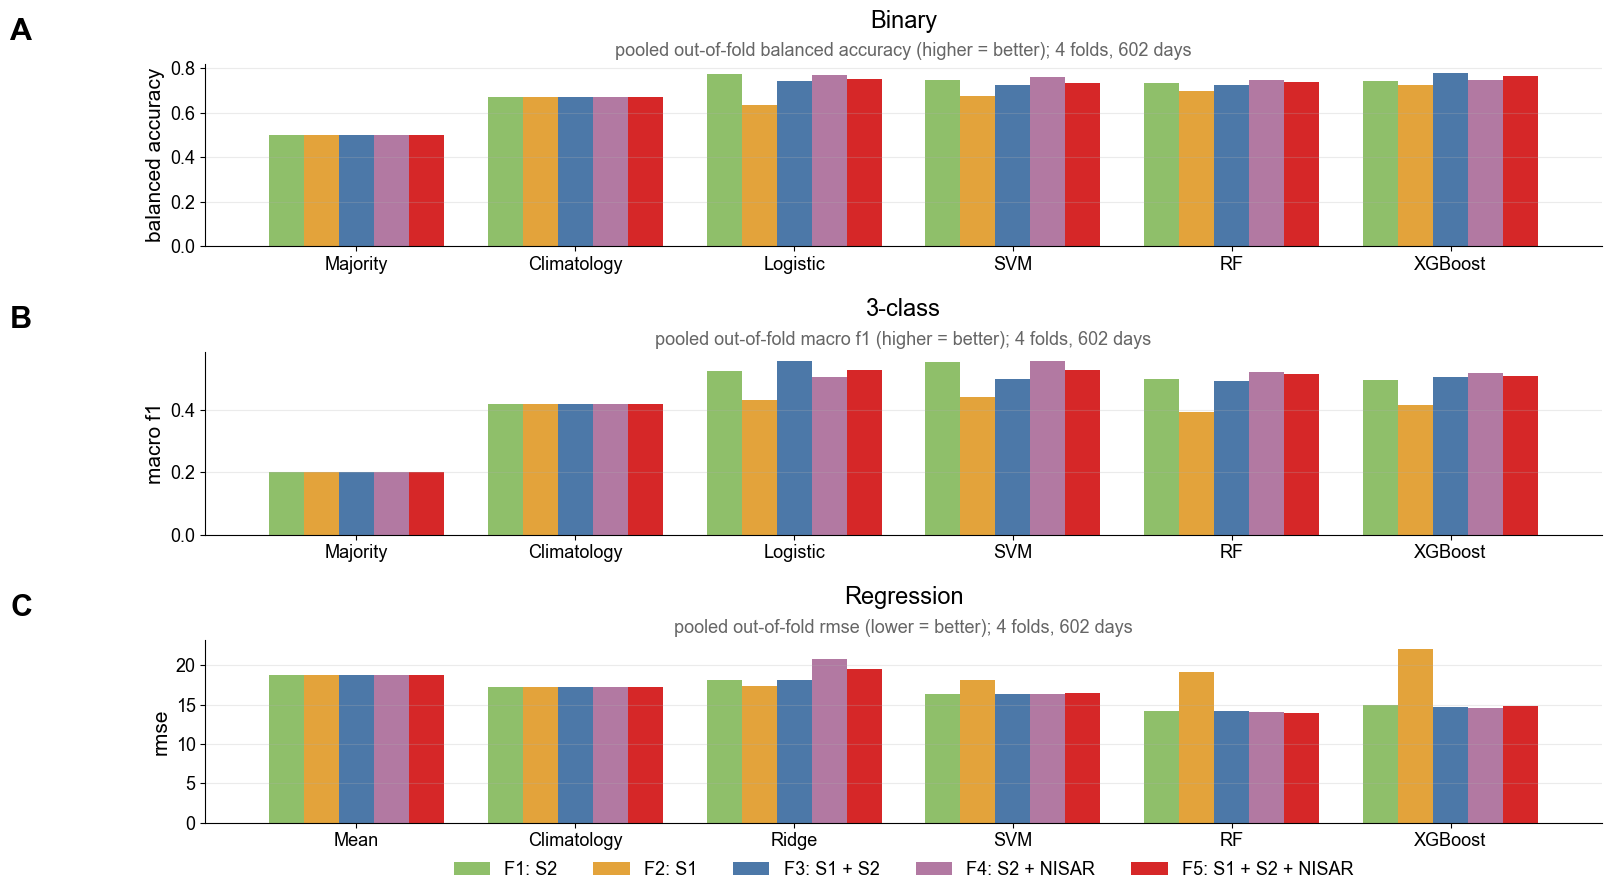

In [289]:
set_colors = dict(zip(FEATURE_SETS, ["#8fbf6a", "#e3a33b", "#4c78a8", "#b279a2", "#d62728"]))
fig, axes = plt.subplots(len(TASKS), 1, figsize=SLIDE_SIZE, layout="constrained")
fig.get_layout_engine().set(h_pad=0.12, hspace=0.06)   # room between stacked panels
for k, (ax, (task, metric)) in enumerate(zip(np.atleast_1d(axes), PRIMARY_METRIC.items())):
    t = pooled[pooled.task == task].pivot(index="model", columns="set", values=metric).loc[list(make_models(task))]
    x = np.arange(len(t)); w = 0.8 / len(FEATURE_SETS)
    for i, s in enumerate(FEATURE_SETS):
        ax.bar(x + (i - (len(FEATURE_SETS) - 1) / 2) * w, t[s], w, label=f"{s}: {' + '.join(FEATURE_SETS[s])}",
               color=set_colors[s])
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel(metric.replace("_", " "))
    ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
    subtitle(ax, f"pooled out-of-fold {metric.replace('_', ' ')}"
                 + (" (lower = better)" if metric in LOWER_IS_BETTER else " (higher = better)")
                 + f"; {len(FOLDS)} folds, {len(df)} days")
    ax.grid(axis="y", alpha=0.25)
    panel_letter(ax, "ABCDEFG"[k])
np.atleast_1d(axes)[-1].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "primary_metric_by_model.png", dpi=SLIDE_DPI)
plt.show()

### Figure: mean ± SD of the fold scores by model and feature set

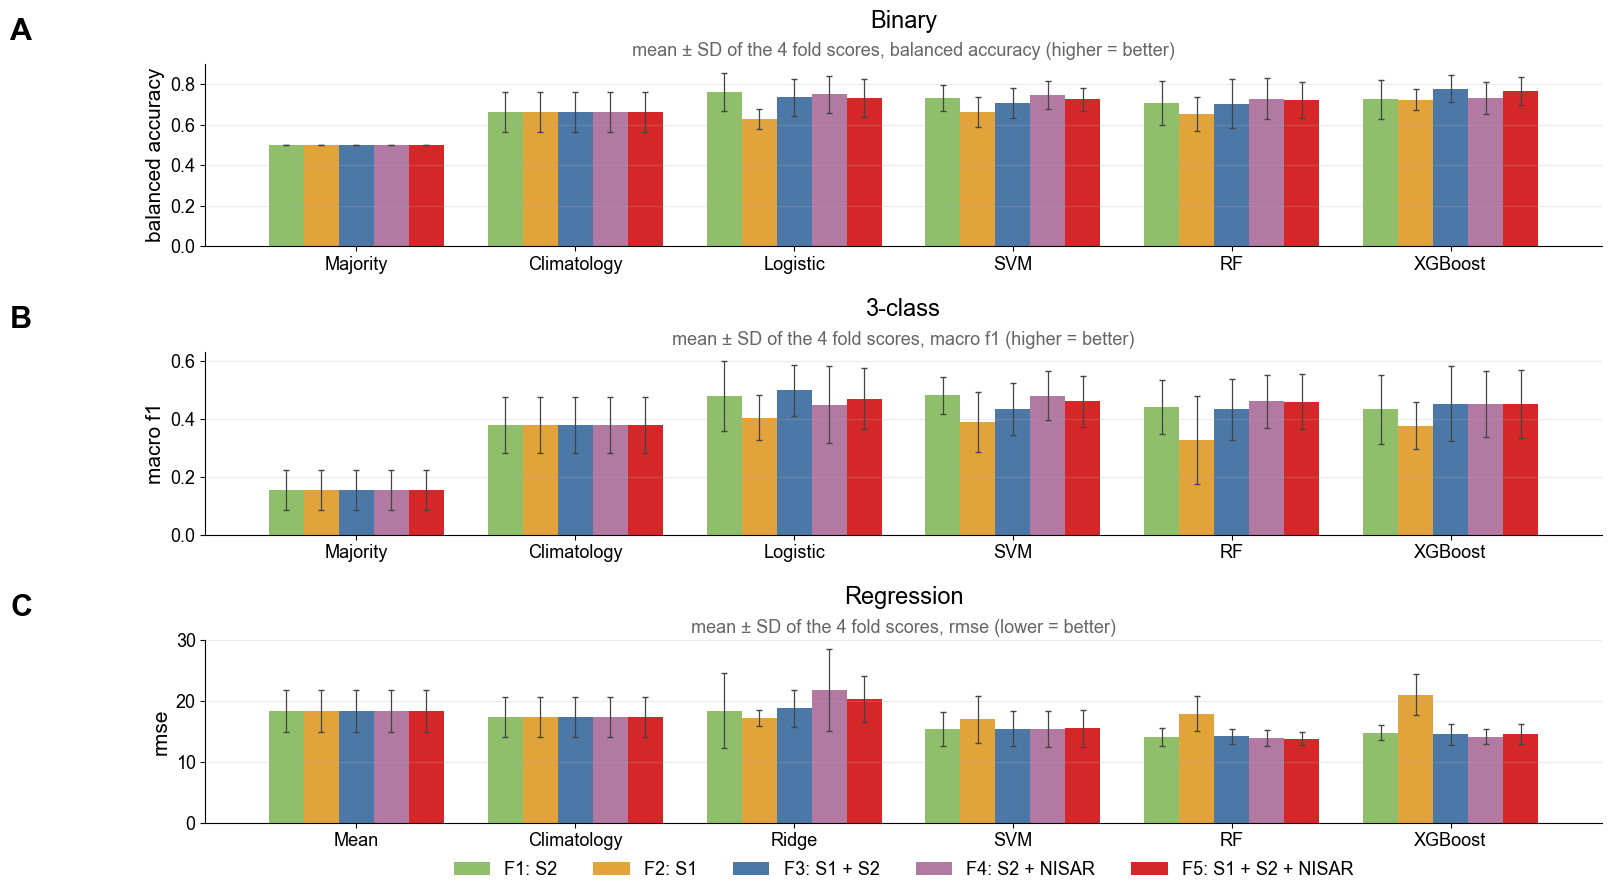

In [290]:
set_colors = dict(zip(FEATURE_SETS, ["#8fbf6a", "#e3a33b", "#4c78a8", "#b279a2", "#d62728"]))
fig, axes = plt.subplots(len(TASKS), 1, figsize=SLIDE_SIZE, layout="constrained")
fig.get_layout_engine().set(h_pad=0.12, hspace=0.06)   # room between stacked panels
for k, (ax, (task, metric)) in enumerate(zip(np.atleast_1d(axes), PRIMARY_METRIC.items())):
    t = fold_stats[fold_stats.task == task]
    mean = t.pivot(index="model", columns="set", values=f"{metric}_mean").loc[list(make_models(task))]
    sd = t.pivot(index="model", columns="set", values=f"{metric}_std").loc[list(make_models(task))]
    x = np.arange(len(mean)); w = 0.8 / len(FEATURE_SETS)
    for i, s in enumerate(FEATURE_SETS):
        ax.bar(x + (i - (len(FEATURE_SETS) - 1) / 2) * w, mean[s], w, yerr=sd[s], capsize=2,
               error_kw=dict(lw=0.9, ecolor="#444444"), label=f"{s}: {' + '.join(FEATURE_SETS[s])}",
               color=set_colors[s])
    ax.set_xticks(x); ax.set_xticklabels(mean.index); ax.set_ylabel(metric.replace("_", " "))
    ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
    subtitle(ax, f"mean ± SD of the {len(FOLDS)} fold scores, {metric.replace('_', ' ')}"
                 + (" (lower = better)" if metric in LOWER_IS_BETTER else " (higher = better)"))
    ax.grid(axis="y", alpha=0.25)
    panel_letter(ax, "ABCDEFG"[k])
np.atleast_1d(axes)[-1].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "fold_mean_sd_by_model.png", dpi=SLIDE_DPI)
plt.show()

### Train vs test scores (overfitting check)

For each fold, the model is scored twice: on the **training** fields it was fit on, and on the held-out **test** field. Bars = mean over the folds, error bars = ± SD. A large train − test gap means the model fits the training fields much better than it predicts a new field.
Note: random forest / ExtraTrees with `min_samples_leaf=5` and boosted trees score high on their own training rows by construction, so compare gaps between models and feature sets rather than reading the train score alone.


binary — balanced_accuracy: train vs test, mean ± SD over folds; gap = how much better train is
set             F1     F2     F3     F4     F5
model                                         
Majority     0.000  0.000  0.000  0.000  0.000
Climatology  0.149  0.149  0.149  0.149  0.149
Logistic     0.181  0.146  0.229  0.206  0.244
SVM          0.162  0.191  0.200  0.163  0.193
RF           0.247  0.311  0.253  0.234  0.239
XGBoost      0.271  0.278  0.223  0.269  0.235

3class — macro_f1: train vs test, mean ± SD over folds; gap = how much better train is
set             F1     F2     F3     F4     F5
model                                         
Majority     0.055  0.055  0.055  0.055  0.055
Climatology  0.206  0.206  0.206  0.206  0.206
Logistic     0.394  0.205  0.407  0.456  0.461
SVM          0.331  0.368  0.394  0.353  0.385
RF           0.488  0.604  0.501  0.475  0.483
XGBoost      0.546  0.615  0.547  0.549  0.547

regression — rmse: train vs test, mean ± SD over folds; gap = 

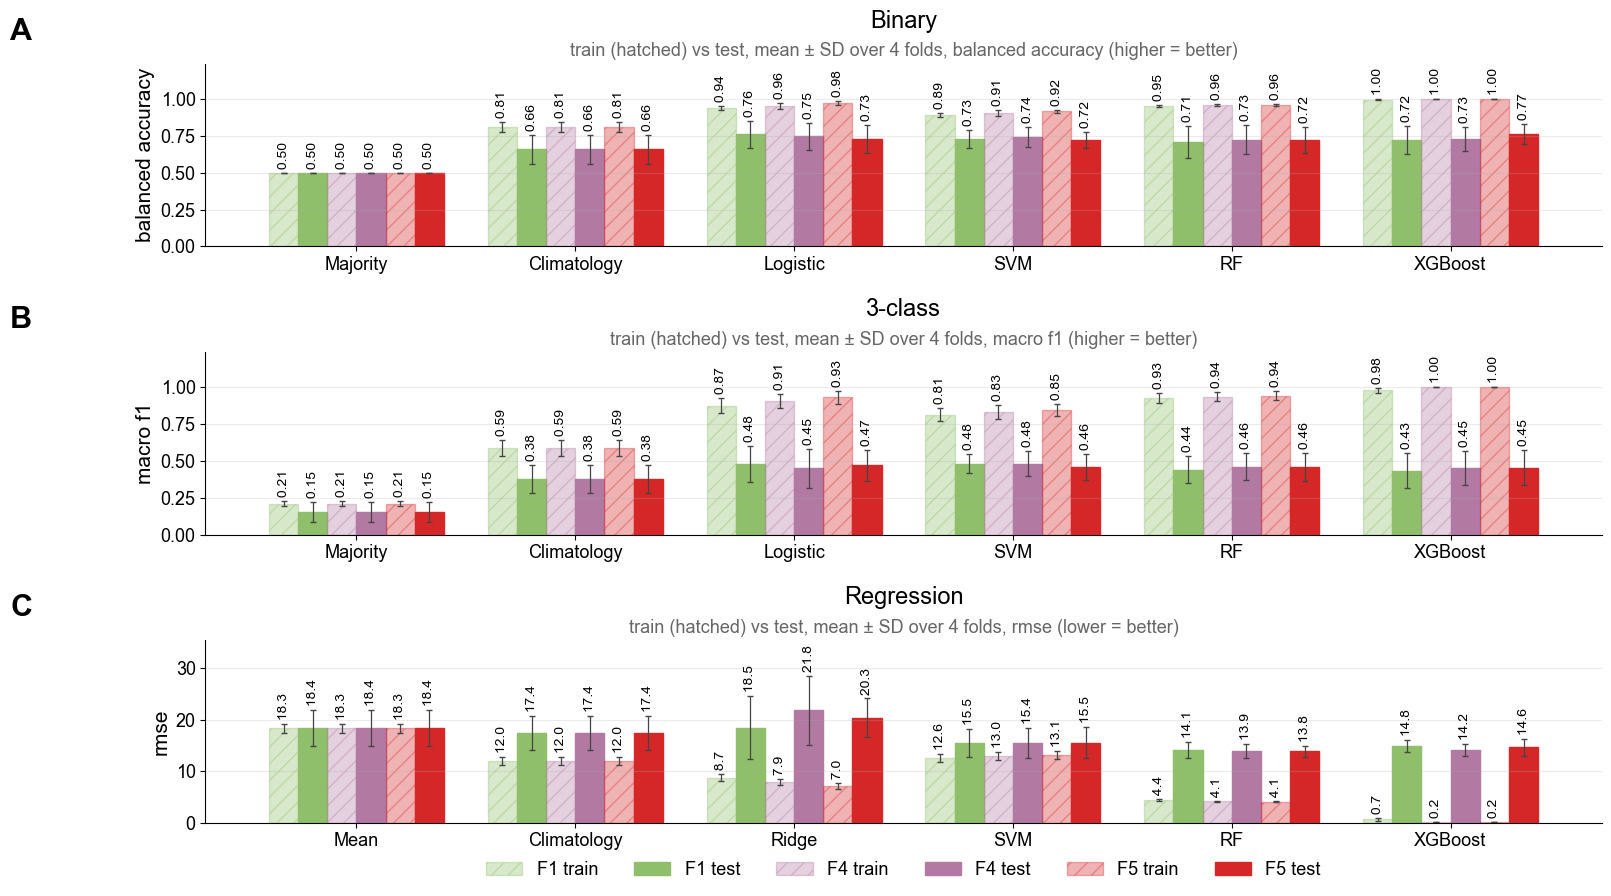

In [291]:
GAP_SETS = ["F1", "F4", "F5"]     # feature sets shown in the figure (all sets are in the table / CSV)

def fold_mean_sd(frame, metric):
    return frame.groupby(["task", "set", "model"])[metric].agg(["mean", "std"])

gap_tabs = {}
for task, metric in PRIMARY_METRIC.items():
    tr = fold_mean_sd(by_fold_train[by_fold_train.task == task], metric)
    te = fold_mean_sd(by_fold[by_fold.task == task], metric)
    g = tr.join(te, lsuffix="_train", rsuffix="_test").reset_index()
    g["gap"] = (g.mean_test - g.mean_train) if metric in LOWER_IS_BETTER else (g.mean_train - g.mean_test)
    gap_tabs[task] = g
    show = g.assign(train=g.mean_train.map("{:.3f}".format) + " ± " + g.std_train.map("{:.3f}".format),
                    test=g.mean_test.map("{:.3f}".format) + " ± " + g.std_test.map("{:.3f}".format))
    print(f"\n{task} — {metric}: train vs test, mean ± SD over folds; gap = how much better train is")
    print(show.pivot(index="model", columns="set", values="gap").loc[list(make_models(task))]
          .round(3).to_string())
train_test = pd.concat(gap_tabs.values(), ignore_index=True)

fig, axes = plt.subplots(len(TASKS), 1, figsize=SLIDE_SIZE, layout="constrained")
fig.get_layout_engine().set(h_pad=0.12, hspace=0.06)   # room between stacked panels
n_bar = 2 * len(GAP_SETS)
for k, (ax, (task, metric)) in enumerate(zip(np.atleast_1d(axes), PRIMARY_METRIC.items())):
    g = gap_tabs[task]
    models = [m for m in make_models(task) if m in set(g.model)]
    x = np.arange(len(models)); w = 0.8 / n_bar
    j = 0
    for s in GAP_SETS:
        gs_ = g[g.set == s].set_index("model").loc[models]
        for part, alpha, hatch in (("train", 0.35, "//"), ("test", 1.0, None)):
            xs = x + (j - (n_bar - 1) / 2) * w
            ax.bar(xs, gs_[f"mean_{part}"], w, yerr=gs_[f"std_{part}"], capsize=2,
                   color=set_colors[s], alpha=alpha, hatch=hatch, edgecolor=set_colors[s],
                   error_kw=dict(lw=0.9, ecolor="#444444"), label=f"{s} {part}")
            # value label above each bar (above its error bar)
            fmt = "{:.1f}" if metric in LOWER_IS_BETTER else "{:.2f}"
            for xi, mu, sd in zip(xs, gs_[f"mean_{part}"], gs_[f"std_{part}"].fillna(0)):
                ax.text(xi, mu + sd, " " + fmt.format(mu), rotation=90, ha="center", va="bottom", fontsize=10)
            j += 1
    ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylabel(metric.replace("_", " "))
    ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
    subtitle(ax, f"train (hatched) vs test, mean ± SD over {len(FOLDS)} folds, {metric.replace('_', ' ')}"
                 + (" (lower = better)" if metric in LOWER_IS_BETTER else " (higher = better)"))
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.18)      # headroom for the value labels
    panel_letter(ax, "ABCDEFG"[k])
np.atleast_1d(axes)[-1].legend(ncol=n_bar, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(OUT_DIR / "train_vs_test_by_model.png", dpi=SLIDE_DPI)
plt.show()

### Figure: observed vs out-of-fold predicted water level (primary model, F4 vs F5)

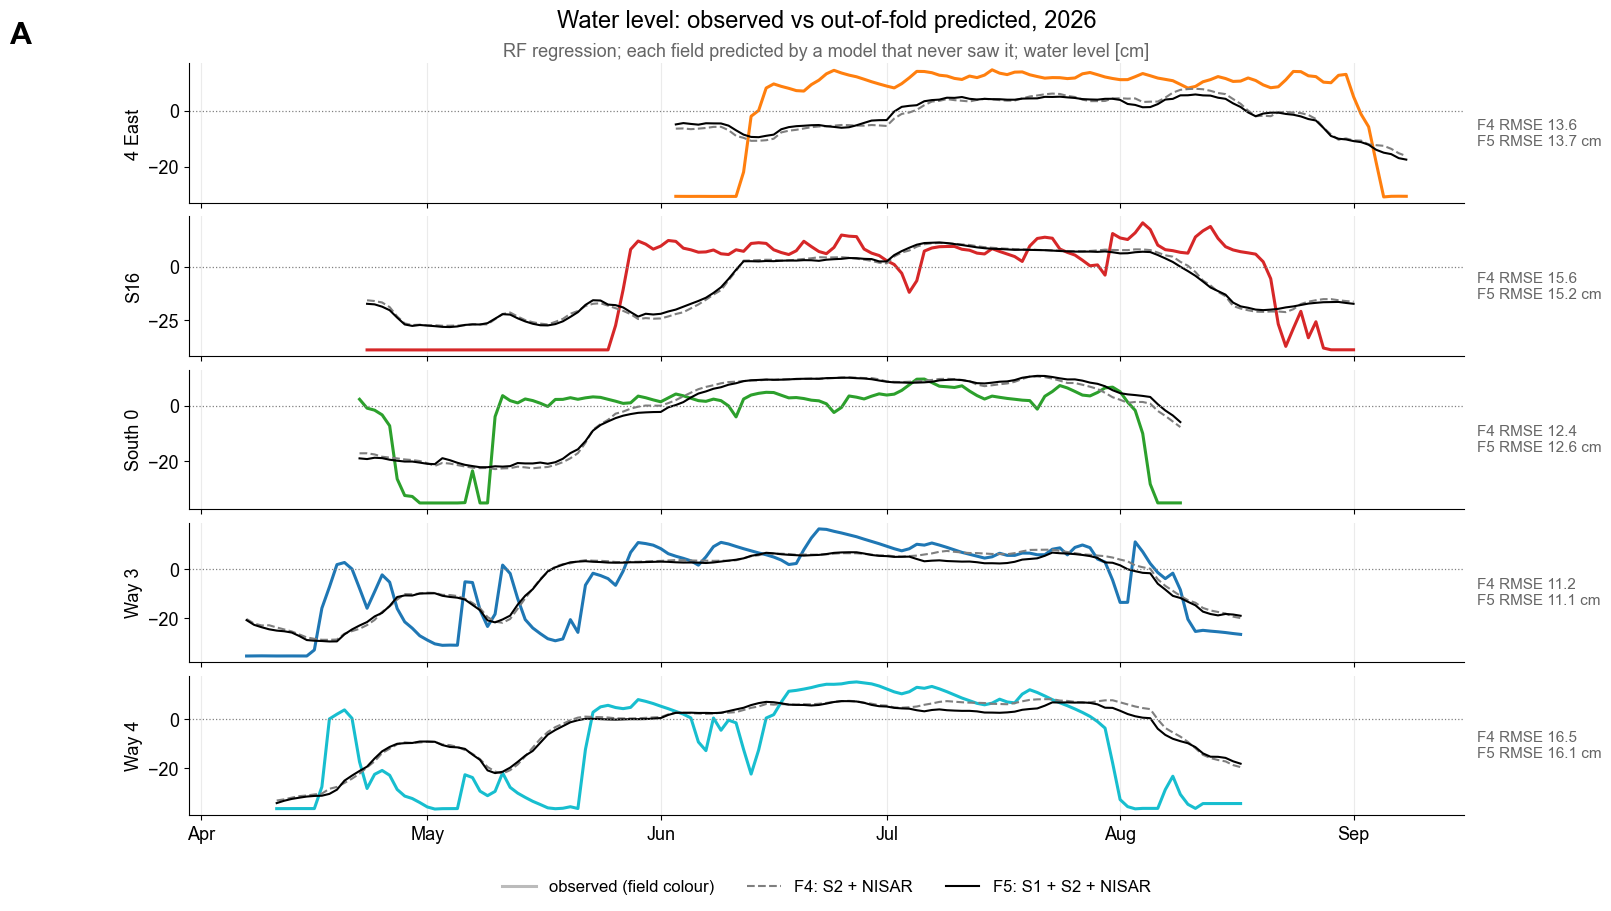

In [292]:
units_list = sorted(df.unit.unique())
r = oof[(oof.task == "regression") & (oof.model == PRIMARY_MODEL)]
fig, axes = plt.subplots(len(units_list), 1, figsize=SLIDE_SIZE, layout="constrained", sharex=True)
WL_SETS = ("F5", "F4")          # feature sets drawn in this figure (with, without)
set_style = {WL_SETS[1]: ("#7f7f7f", "--"), WL_SETS[0]: ("#000000", "-")}   # predictions: neutral, so field colours stay distinct
for k, (ax, gid) in enumerate(zip(axes, units_list)):
    m = (df.unit == gid).values
    fld = df.field[m].iloc[0]
    ax.plot(df.date[m], df.water_cm[m], color=FIELD_COLORS.get(fld, "k"), lw=2.2, label="observed")
    txt = []
    for s, (c, ls) in set_style.items():
        rr = r[r.set == s].set_index("row").loc[np.where(m)[0]]
        ax.plot(df.date[m], rr.pred.values, color=c, lw=1.5, ls=ls, label=f"{s}: {' + '.join(FEATURE_SETS[s])}")
        txt.append(f"{s} RMSE {np.sqrt(np.mean((rr.pred.values - rr.y.values) ** 2)):.1f}")
    ax.axhline(0, color="grey", lw=0.9, ls=":")
    ax.set_ylabel(gid if gid == fld else f"{gid}\n({fld})", fontsize=13)
    ax.text(1.01, 0.5, "\n".join(txt) + " cm", transform=ax.transAxes, va="center", fontsize=11, color="#666666")
    ax.grid(axis="x", alpha=0.25)
axes[0].set_title("Water level: observed vs out-of-fold predicted, 2026", pad=26)
subtitle(axes[0], f"{PRIMARY_MODEL} regression; each field predicted by a model that never saw it; water level [cm]")
from matplotlib.lines import Line2D
axes[-1].legend(handles=[Line2D([], [], color="#bbbbbb", lw=2.2, label="observed (field colour)")] +
                        [Line2D([], [], color=c, ls=ls, lw=1.5, label=f"{s}: {' + '.join(FEATURE_SETS[s])}")
                         for s, (c, ls) in set_style.items()],
                ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.35), fontsize=12)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
panel_letter(axes[0], "A")
fig.savefig(OUT_DIR / "oof_water_level_primary.png", dpi=SLIDE_DPI)
plt.show()

### Binary: confusion matrices and the final drydown (F1 vs F4 vs F5)

Per field, out-of-fold predictions of `CM_MODEL` (the field was held out when its predictions were made).
**Final drydown** = the days after the last day with water ≥ 0 cm, i.e. the end-of-season drainage before harvest.
The strips show the observed label and each feature set's predicted label, day by day.

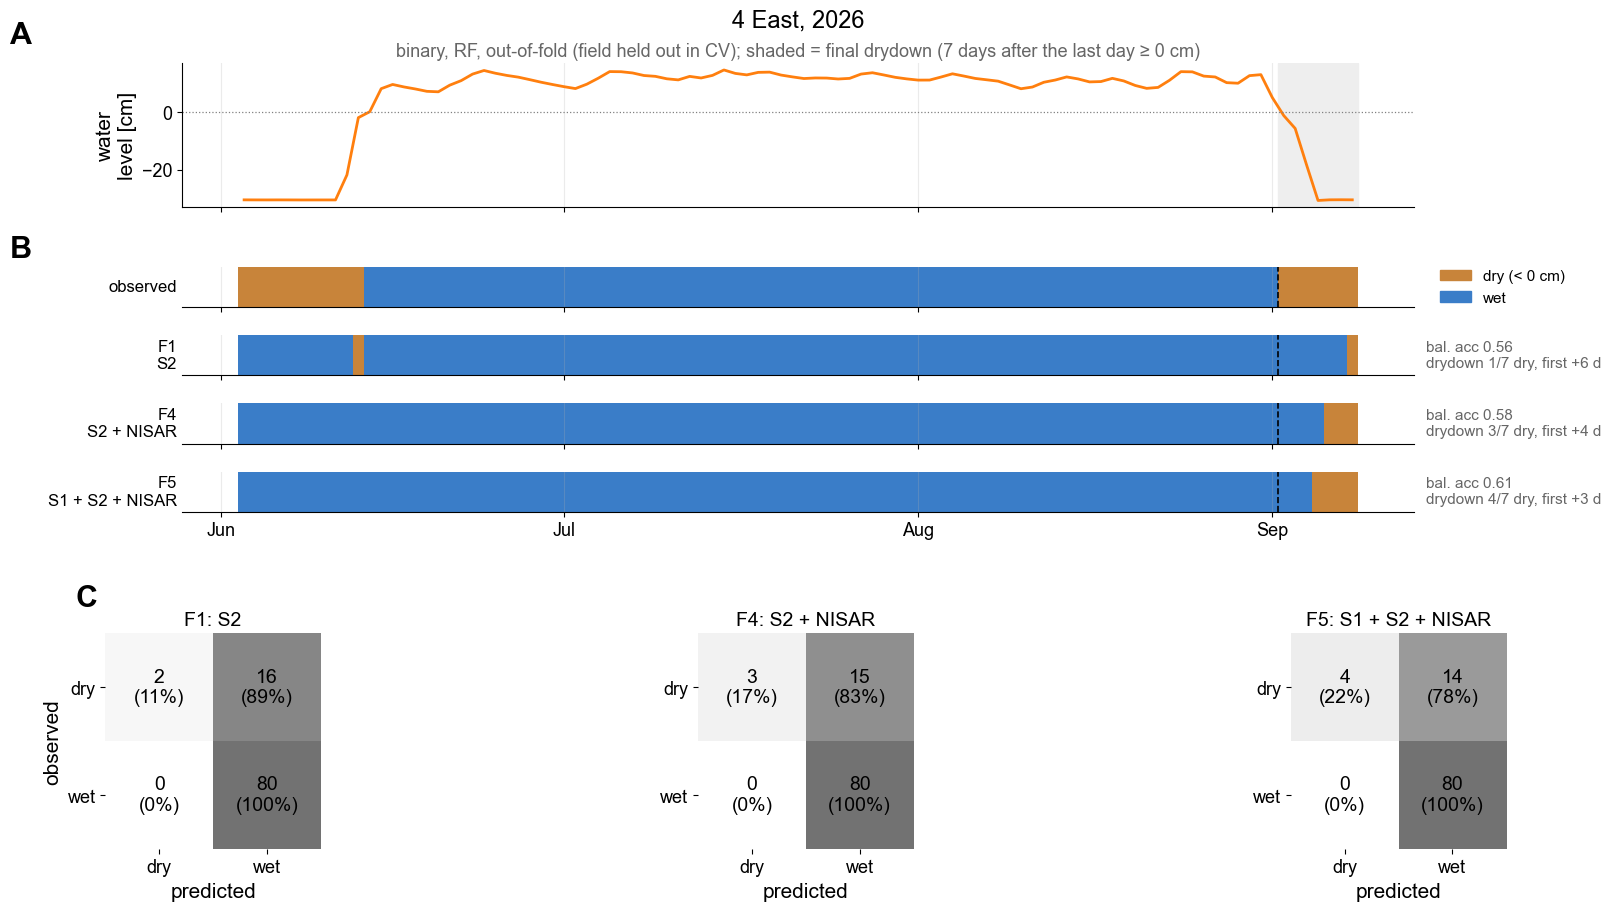

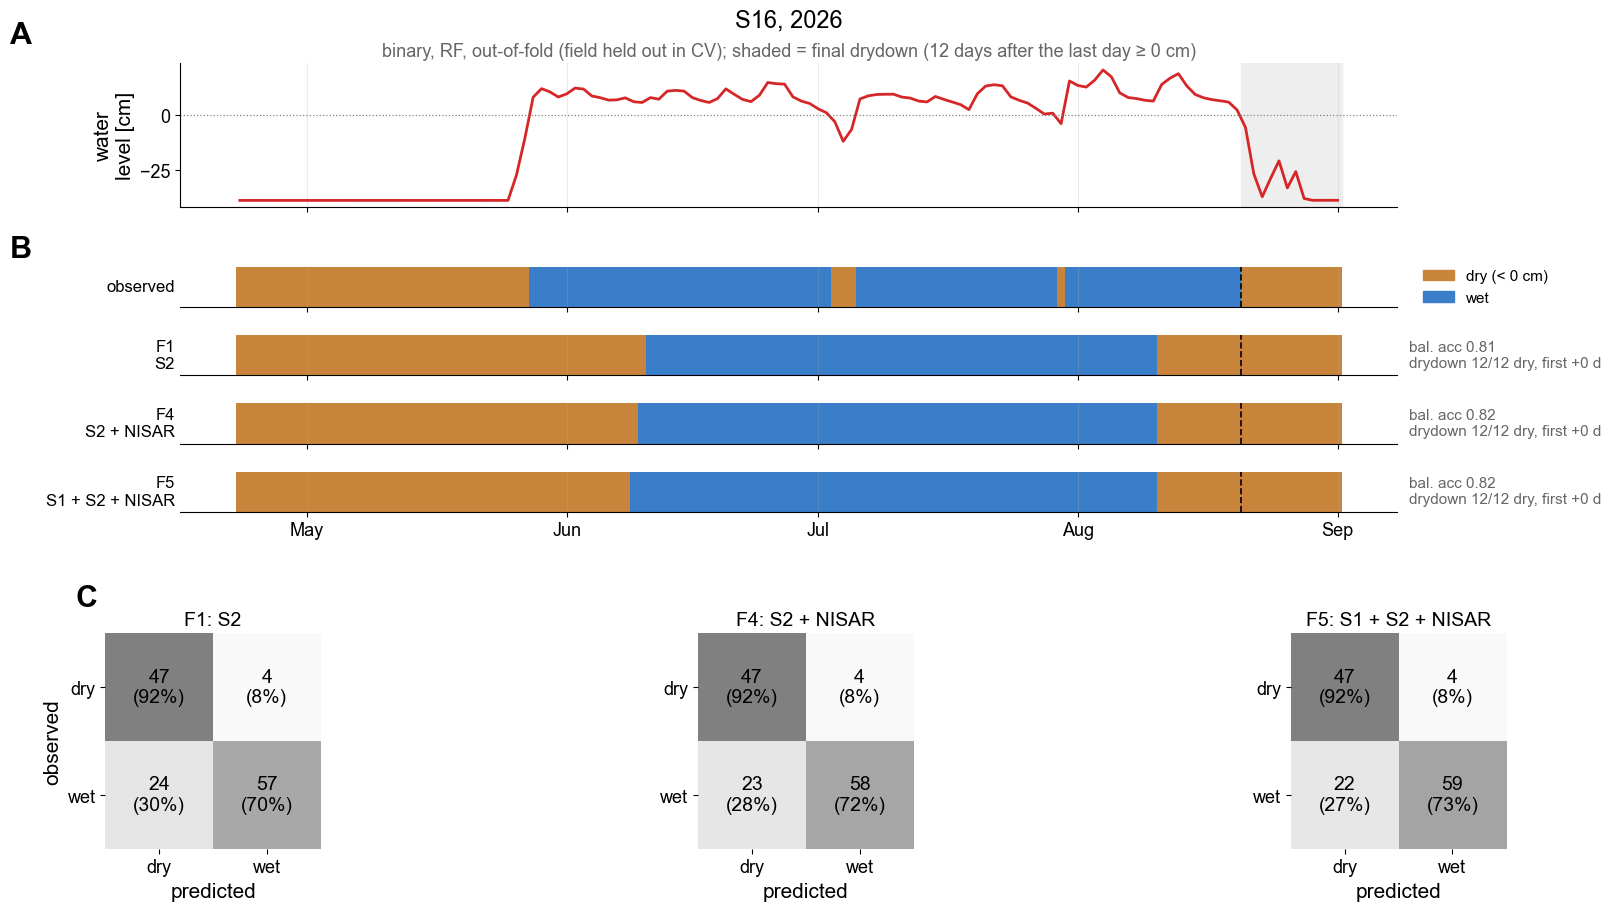

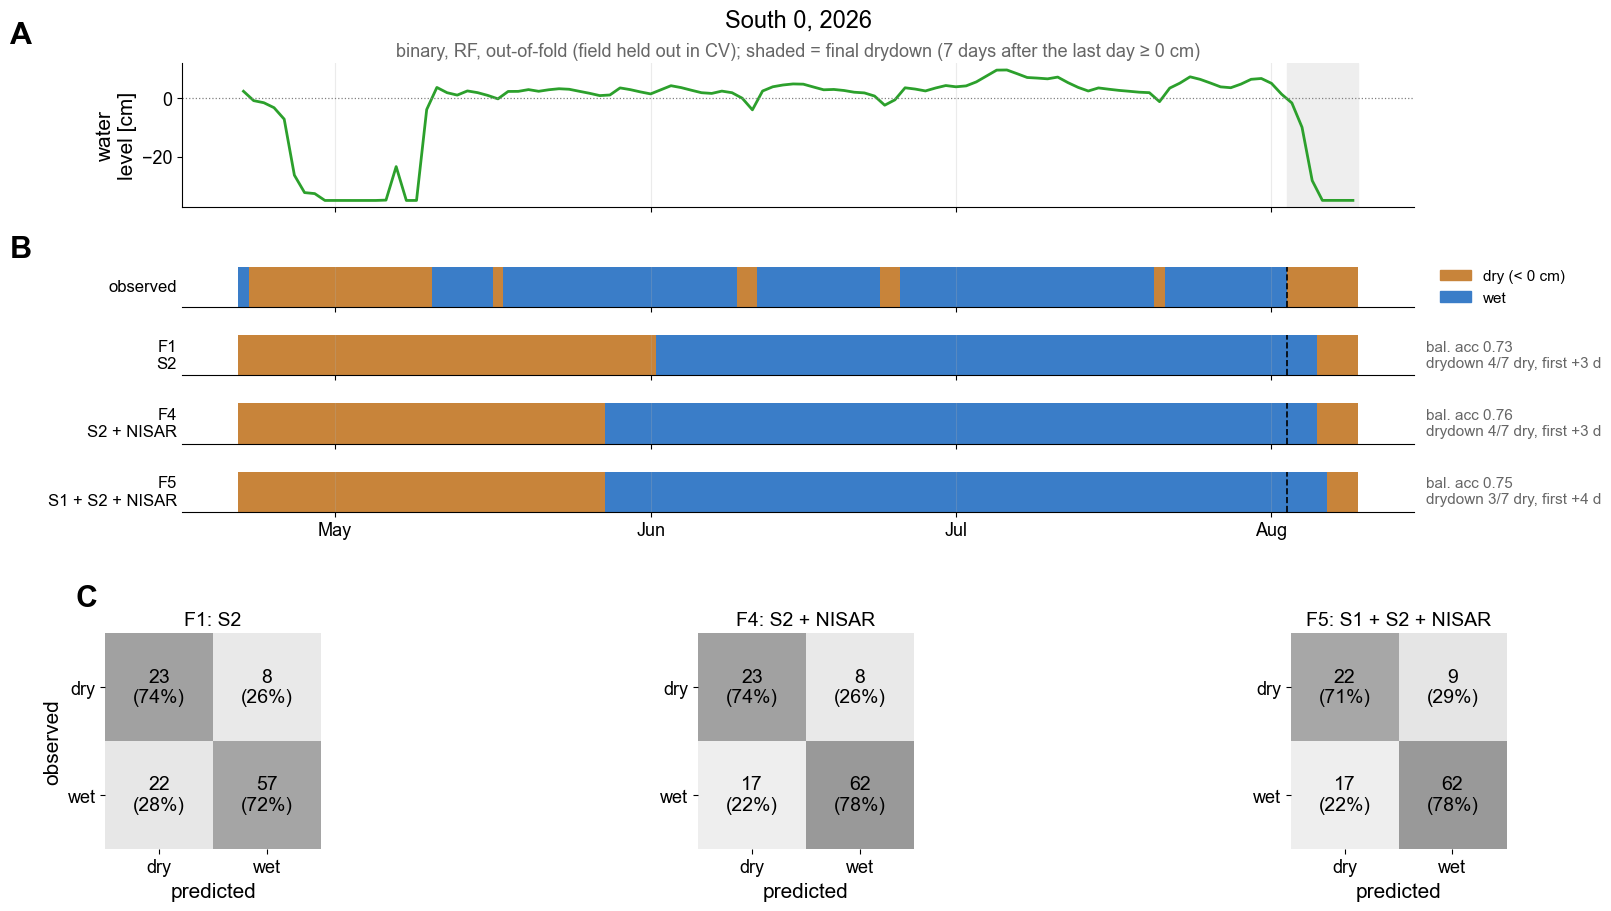

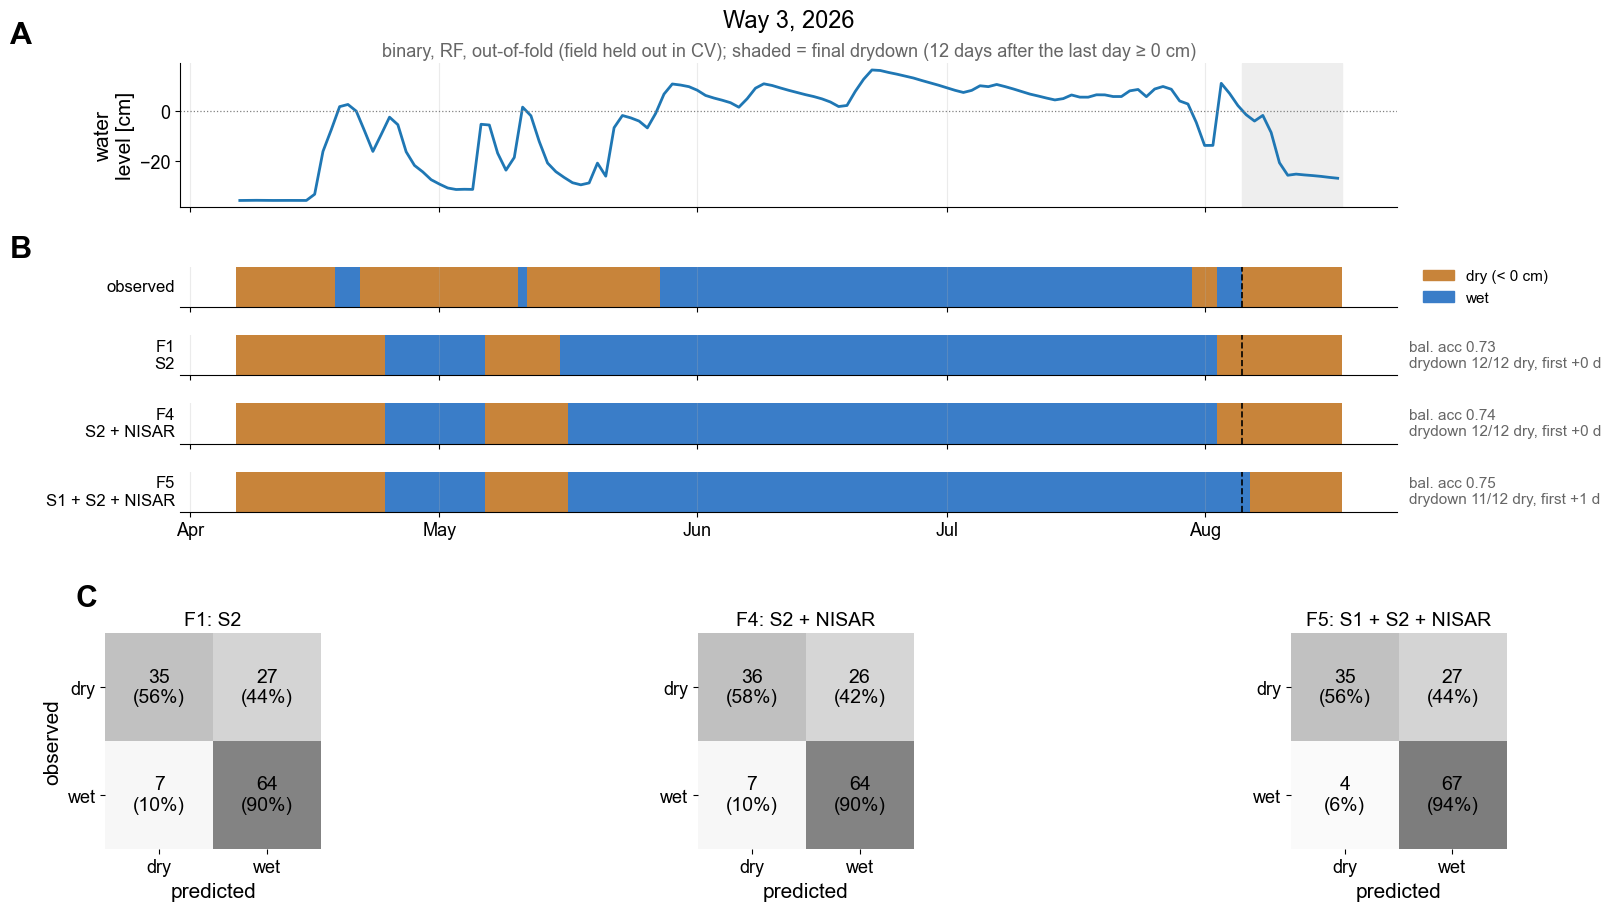

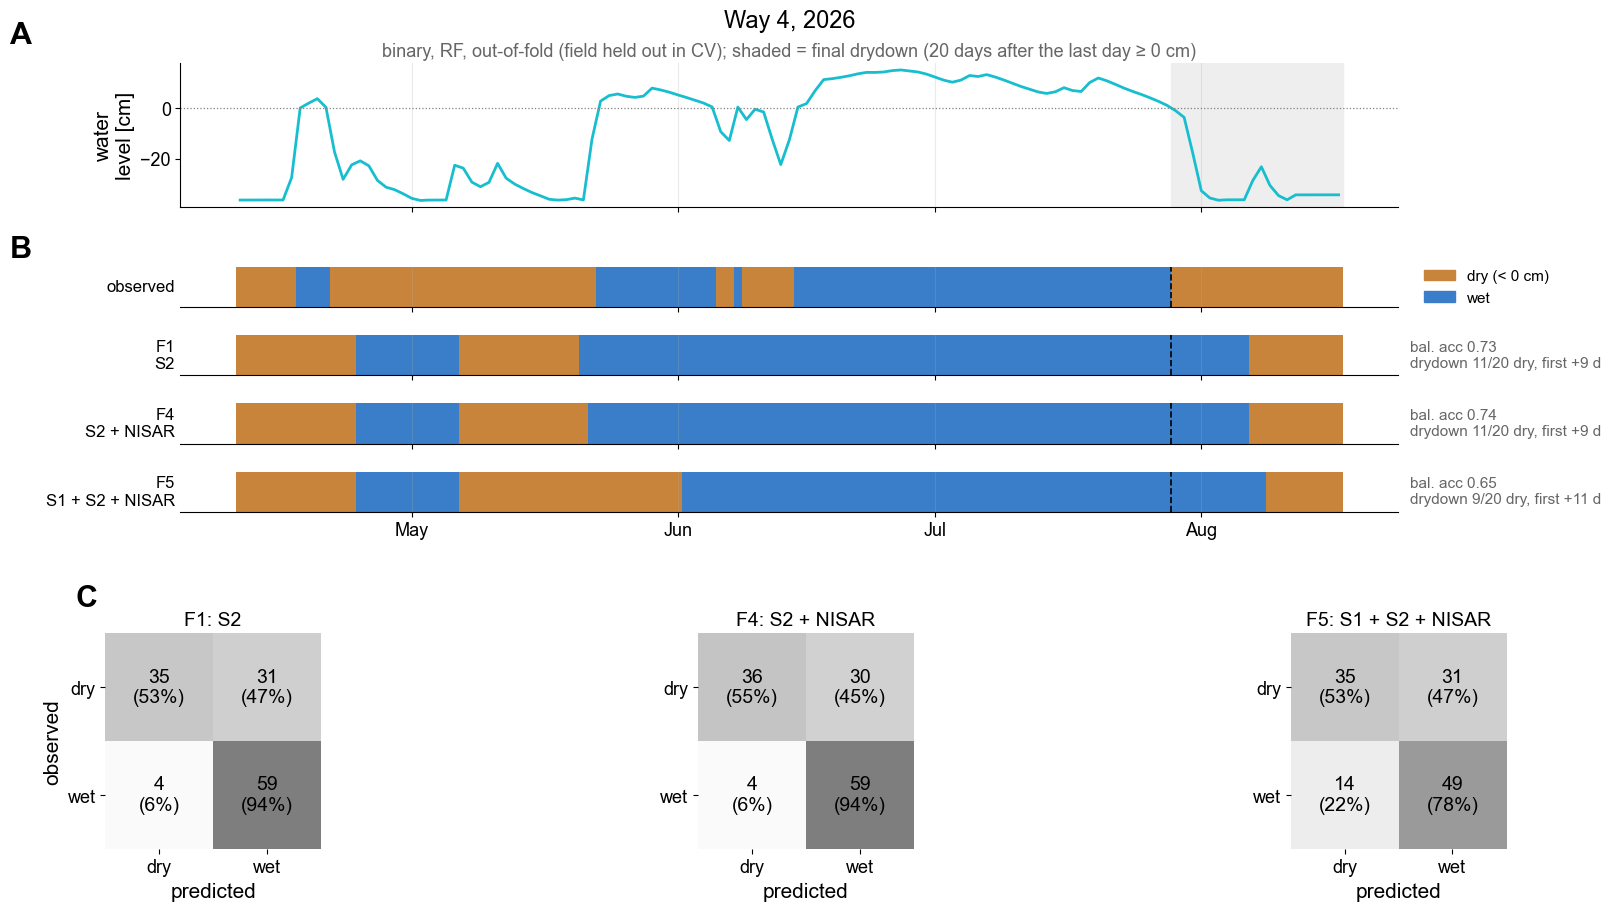

final drydown = days after the last day with water >= 0 cm
  field set  balanced_accuracy  dry_days_all  dry_predicted_dry_all  final_dry_days  final_dry_predicted_dry  final_dry_share  days_to_first_dry_pred
 4 East  F1              0.556            18                      2               7                        1            0.143                       6
 4 East  F4              0.583            18                      3               7                        3            0.429                       4
 4 East  F5              0.611            18                      4               7                        4            0.571                       3
    S16  F1              0.813            51                     47              12                       12            1.000                       0
    S16  F4              0.819            51                     47              12                       12            1.000                       0
    S16  F5              0.825           

In [293]:
# ---- settings for this section ----
CM_MODEL  = PRIMARY_MODEL            # model to show
CM_SETS   = ["F1", "F4", "F5"]       # feature sets to compare
CM_FIELDS = None                     # None = every field, or e.g. ["S16"]
DRY_COLOR, WET_COLOR = "#c8843a", "#3a7dc8"

b = oof[(oof.task == "binary") & (oof.model == CM_MODEL) & (oof.set.isin(CM_SETS))]
b = b.merge(df[["field", "date", "water_cm"]], left_on="row", right_index=True)

# Final drydown = days after the LAST day with water >= DRY_2C (end-of-season drainage before harvest).
last_wet = df[df.water_cm >= DRY_2C].groupby("field").date.max()
b["final_dry"] = b.date > b.field.map(last_wet)


def drydown_stats(r):
    fd = r[r.final_dry]
    n_ok = int((fd.pred == 0).sum())
    return dict(final_dry_days=len(fd), final_dry_predicted_dry=n_ok,
                final_dry_share=n_ok / len(fd) if len(fd) else np.nan,
                # days from the first final-drydown day to the first day predicted dry in it
                days_to_first_dry_pred=(fd[fd.pred == 0].date.min() - fd.date.min()).days if n_ok else np.nan)


def binary_field_figure(field):
    bf = b[b.field == field]
    obs = bf[bf.set == CM_SETS[0]].sort_values("date")
    dd = obs[obs.final_dry]
    rows = [("observed", obs.y.values, None)] + [
        (s, bf[bf.set == s].sort_values("date").pred.values, bf[bf.set == s]) for s in CM_SETS]

    fig = plt.figure(figsize=SLIDE_SIZE, layout="constrained")
    ratios = [1.5] + [0.42] * len(rows) + [0.3, 3.4]                 # A, B strips, spacer, C
    gs = fig.add_gridspec(len(ratios), 1, height_ratios=ratios, hspace=0.18)
    axes = [fig.add_subplot(gs[0])]
    for i in range(len(rows)):
        axes.append(fig.add_subplot(gs[1 + i], sharex=axes[0]))

    # ---- A: water level, final drydown shaded --------------------------------
    ax = axes[0]
    ax.plot(obs.date, obs.water_cm, lw=2, color=FIELD_COLORS.get(field, "k"))
    ax.axhline(DRY_2C, color="grey", lw=0.9, ls=":")
    ax.set_ylabel("water\nlevel [cm]")
    ax.set_title(f"{field}, 2026", pad=26)
    subtitle(ax, f"binary, {CM_MODEL}, out-of-fold (field held out in CV); "
                 f"shaded = final drydown ({len(dd)} days after the last day ≥ {DRY_2C} cm)")
    panel_letter(ax, "A")

    # ---- B: one strip per label series ---------------------------------------
    for ax, (lab, vals, r) in zip(axes[1:], rows):
        ax.bar(obs.date, 1, width=1.0, color=np.where(vals == 0, DRY_COLOR, WET_COLOR), align="center")
        ax.set_ylim(0, 1); ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.set_ylabel(lab if lab == "observed" else f"{lab}\n{' + '.join(FEATURE_SETS[lab])}",
                      fontsize=12, rotation=0, ha="right", va="center")
        if r is not None:
            st = drydown_stats(r)
            ba = balanced_accuracy_score(r.y, r.pred) if r.y.nunique() == 2 else np.nan
            first = "–" if np.isnan(st["days_to_first_dry_pred"]) else f"+{st['days_to_first_dry_pred']:.0f} d"
            ax.text(1.01, 0.5, f"bal. acc {ba:.2f}\ndrydown {st['final_dry_predicted_dry']}/{st['final_dry_days']}"
                               f" dry, first {first}", transform=ax.transAxes, va="center",
                    fontsize=11, color="#666666")
    panel_letter(axes[1], "B")
    axes[1].legend(handles=[Patch(color=DRY_COLOR, label=f"dry (< {DRY_2C} cm)"),
                            Patch(color=WET_COLOR, label="wet")],
                   ncol=1, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=11)
    if len(dd):
        start = dd.date.min() - pd.Timedelta(hours=12)
        axes[0].axvspan(start, dd.date.max() + pd.Timedelta(hours=12), color="#eeeeee", zorder=0)
        for ax in axes[1:]:                                # strips are filled: mark drydown start instead
            ax.axvline(start, color="k", lw=1.2, ls="--")
    for ax in axes:
        ax.grid(axis="x", alpha=0.25)
    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    # ---- C: confusion matrices -----------------------------------------------
    sub = gs[-1].subgridspec(1, len(CM_SETS), wspace=0.35)
    for j, s in enumerate(CM_SETS):
        r = bf[bf.set == s]
        cm = confusion_matrix(r.y, r.pred, labels=[0, 1])
        pct = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax = fig.add_subplot(sub[0, j])
        ax.imshow(pct, cmap="Greys", vmin=0, vmax=1.6)
        for (i, k), v in np.ndenumerate(cm):
            ax.text(k, i, f"{v}\n({pct[i, k]:.0%})", ha="center", va="center", fontsize=14)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["dry", "wet"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["dry", "wet"])
        ax.set_xlabel("predicted")
        if j == 0:
            ax.set_ylabel("observed")
        ax.set_title(f"{s}: {' + '.join(FEATURE_SETS[s])}", fontsize=14)
        for sp in ax.spines.values():
            sp.set_visible(False)
        if j == 0:
            panel_letter(ax, "C")
    return fig


summary = []
for field in (CM_FIELDS or sorted(df.field.unique())):
    fig = binary_field_figure(field)
    fig.savefig(OUT_DIR / f"binary_cm_{field.replace(' ', '_')}.png", dpi=SLIDE_DPI)
    plt.show()
    for s in CM_SETS:
        r = b[(b.field == field) & (b.set == s)]
        summary.append(dict(field=field, set=s,
                            balanced_accuracy=balanced_accuracy_score(r.y, r.pred) if r.y.nunique() == 2 else np.nan,
                            dry_days_all=int((r.y == 0).sum()), dry_predicted_dry_all=int(((r.y == 0) & (r.pred == 0)).sum()),
                            **drydown_stats(r)))

cm_summary = pd.DataFrame(summary)
print("final drydown = days after the last day with water >= 0 cm")
print(cm_summary.round(3).to_string(index=False))
cm_summary.to_csv(OUT_DIR / "binary_final_drydown_summary.csv", index=False)

### Feature contributions: SHAP (random forest and XGBoost)

SHAP splits each prediction into one contribution per feature (how much that feature moved the prediction away from the model's average). Values are computed **out-of-fold**: each field-day is explained by the model that was trained without its field.
* Binary: contribution to "wet" — random forest in **probability** units, XGBoost in **log-odds** units (XGBoost's own exact TreeSHAP; the `shap` package cannot read XGBoost 3.x models). Regression: **cm**.
* Units differ between models, so compare **rankings** across models, not bar lengths.
* Variable importance = mean |SHAP| summed over the 14 lags (and the missing-value indicator columns of that variable).

In [294]:
import shap

RUN_SHAP    = True
SHAP_MODELS = ["RF", "XGBoost"]
SHAP_TASKS  = ["binary", "regression"]   # 3-class has one SHAP set per class; left out
SHAP_SETS   = ["F5"]                     # feature sets to explain
SHAP_TOP    = 15                         # lag-features shown in the beeswarm
SENSOR_OF   = {p: s for s, p in SENSORS.items()}            # "s2_" -> "S2"
SENSOR_COLORS = {"S2": "#8fbf6a", "S1": "#e3a33b", "NISAR": "#b279a2"}


def split_name(col):
    """'missingindicator_s1_vh_db_lag3' / 's1_vh_db_lag3' -> (sensor, variable, lag)."""
    base = col.replace("missingindicator_", "")
    stem, lag = base.rsplit("_lag", 1)
    prefix = next(p for p in SENSOR_OF if stem.startswith(p))
    return SENSOR_OF[prefix], stem[len(prefix):], int(lag)


def explain(model, X_te):
    """SHAP values (rows x features, as a DataFrame) for one fitted model on held-out rows.
    Binary: contribution to class 1 (wet). RF classifier: probability units; XGBoost
    classifier: log-odds units; regressors: cm."""
    if hasattr(model, "steps"):                        # sklearn pipeline: imputer (+ indicators) -> forest
        pre, est = model[:-1], model[-1]
        Xt = pre.transform(X_te)
        names = list(pre.get_feature_names_out(X_te.columns))
    else:                                              # XGBoost (wrapper or regressor), raw columns
        # XGBoost's own exact TreeSHAP (pred_contribs); the shap package cannot read XGBoost 3.x models.
        import xgboost as xgb
        est = model.model_ if hasattr(model, "model_") else model
        contrib = est.get_booster().predict(xgb.DMatrix(X_te.values, feature_names=list(X_te.columns)),
                                            pred_contribs=True)
        return pd.DataFrame(contrib[:, :-1], columns=list(X_te.columns), index=X_te.index)   # last col = bias
    sv = shap.TreeExplainer(est).shap_values(Xt, check_additivity=False)
    if isinstance(sv, list):                           # older shap: one array per class
        sv = sv[-1]
    if sv.ndim == 3:                                   # (rows, features, classes) -> class 1
        sv = sv[:, :, -1]
    return pd.DataFrame(sv, columns=names, index=X_te.index)


shap_long, shap_vals = [], {}
if RUN_SHAP:
    t0 = time.time()
    for task in SHAP_TASKS:
        y = df[TASKS[task]].values.astype(float if task == "regression" else int)
        for set_name in SHAP_SETS:
            X = df[feature_cols(set_name)]
            for name in SHAP_MODELS:
                est = make_models(task)[name][0]
                parts = []
                for g in FOLDS:                        # same folds: each row explained by a model that never saw it
                    te = groups == g; tr = ~te
                    m = clone(est).fit(X[tr], y[tr])
                    parts.append(explain(m, X[te]))
                S = pd.concat(parts).reindex(X.index).fillna(0.0)    # feature absent in a fold -> 0
                shap_vals[(task, set_name, name)] = S
                # per feature: mean |SHAP| over all rows; indicator columns are folded into their feature
                per_col = S.abs().mean()
                for col, v in per_col.items():
                    sensor, var, lag = split_name(col)
                    shap_long.append(dict(task=task, set=set_name, model=name, column=col, sensor=sensor,
                                          variable=var, lag=lag, mean_abs_shap=v))
                print(f"{task} {set_name} {name}: done ({time.time() - t0:.0f} s)")
    shap_imp = pd.DataFrame(shap_long)
    shap_var = (shap_imp.groupby(["task", "set", "model", "sensor", "variable"]).mean_abs_shap.sum()
                .reset_index().sort_values(["task", "set", "model", "mean_abs_shap"], ascending=[True, True, True, False]))
    shap_sensor = shap_imp.groupby(["task", "set", "model", "sensor"]).mean_abs_shap.sum().reset_index()
    shap_sensor["share"] = shap_sensor.mean_abs_shap / shap_sensor.groupby(["task", "set", "model"]).mean_abs_shap.transform("sum")
    print("\nShare of total mean |SHAP| by sensor")
    print(shap_sensor.pivot_table(index=["task", "set", "model"], columns="sensor", values="share").round(3).to_string())
    print("\nTop 10 variables (mean |SHAP| summed over the 14 lags)")
    for key, g in shap_var.groupby(["task", "set", "model"]):
        print(f"\n{key[0]} {key[1]} {key[2]}")
        print(g.head(10)[["sensor", "variable", "mean_abs_shap"]].round(4).to_string(index=False))

binary F5 RF: done (2 s)
binary F5 XGBoost: done (4 s)
regression F5 RF: done (7 s)
regression F5 XGBoost: done (10 s)

Share of total mean |SHAP| by sensor
sensor                  NISAR     S1     S2
task       set model                       
binary     F5  RF       0.040  0.092  0.868
               XGBoost  0.115  0.208  0.677
regression F5  RF       0.060  0.082  0.858
               XGBoost  0.103  0.182  0.715

Top 10 variables (mean |SHAP| summed over the 14 lags)

binary F5 RF
sensor      variable  mean_abs_shap
    S2  solar_zenith         0.0813
    S2            B5         0.0654
    S2 solar_azimuth         0.0487
    S2           B12         0.0405
    S2            B4         0.0384
    S2            B3         0.0367
    S2          ndwi         0.0321
    S2           B11         0.0298
    S2          ndvi         0.0279
    S2            B2         0.0197

binary F5 XGBoost
sensor       variable  mean_abs_shap
    S2             B5         1.3533
    S1        inc_de

### Figures: SHAP importance per variable, and the top lag-features

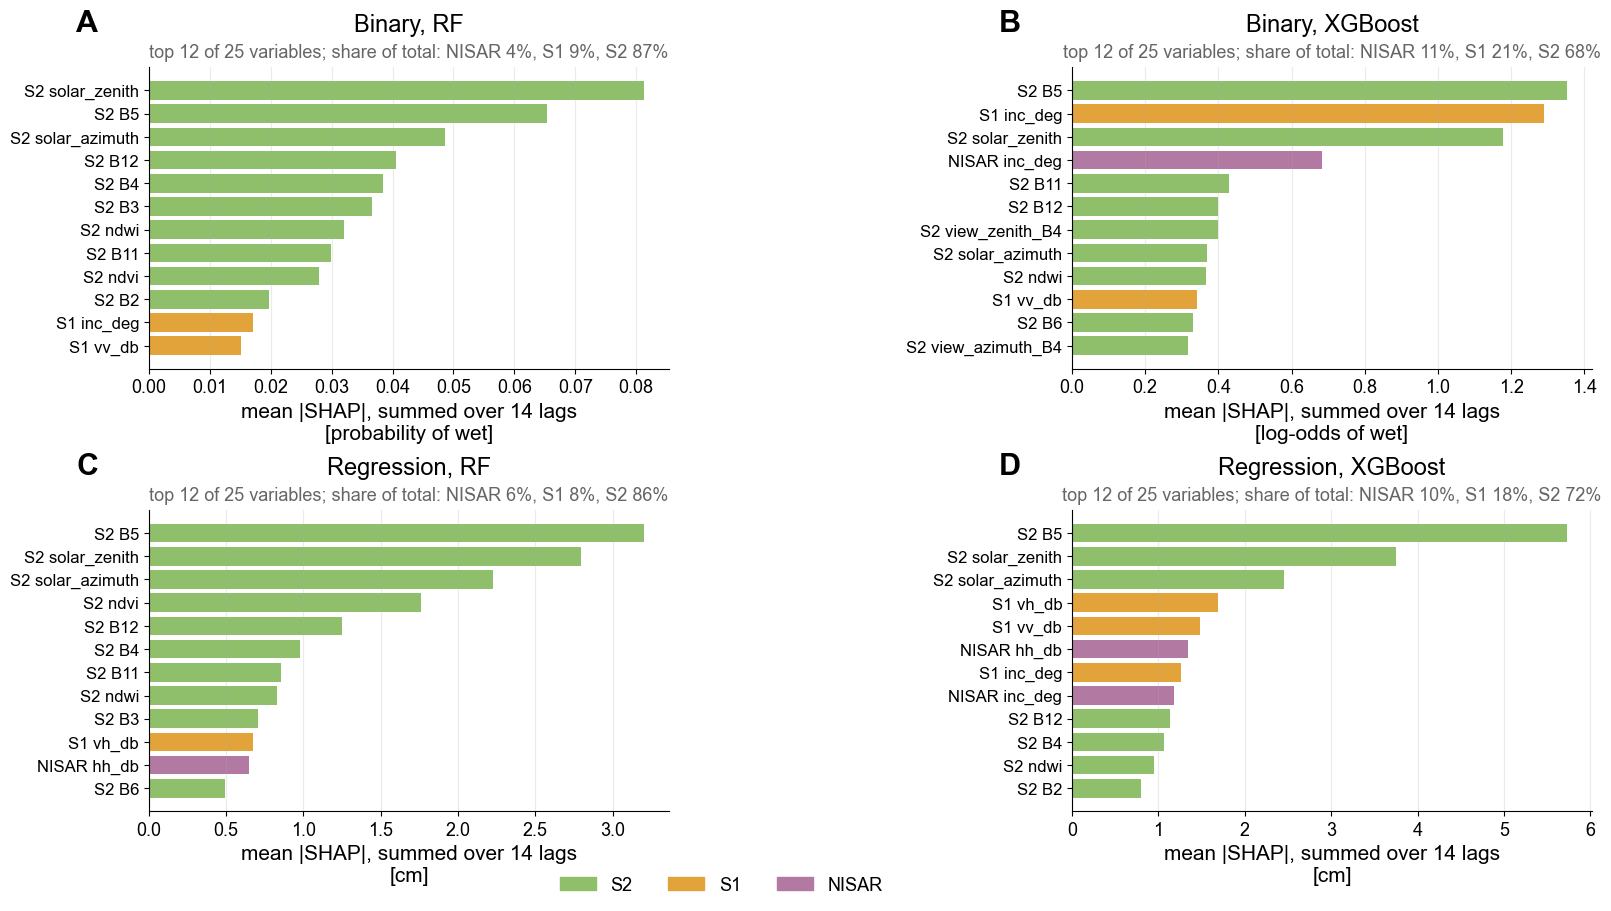

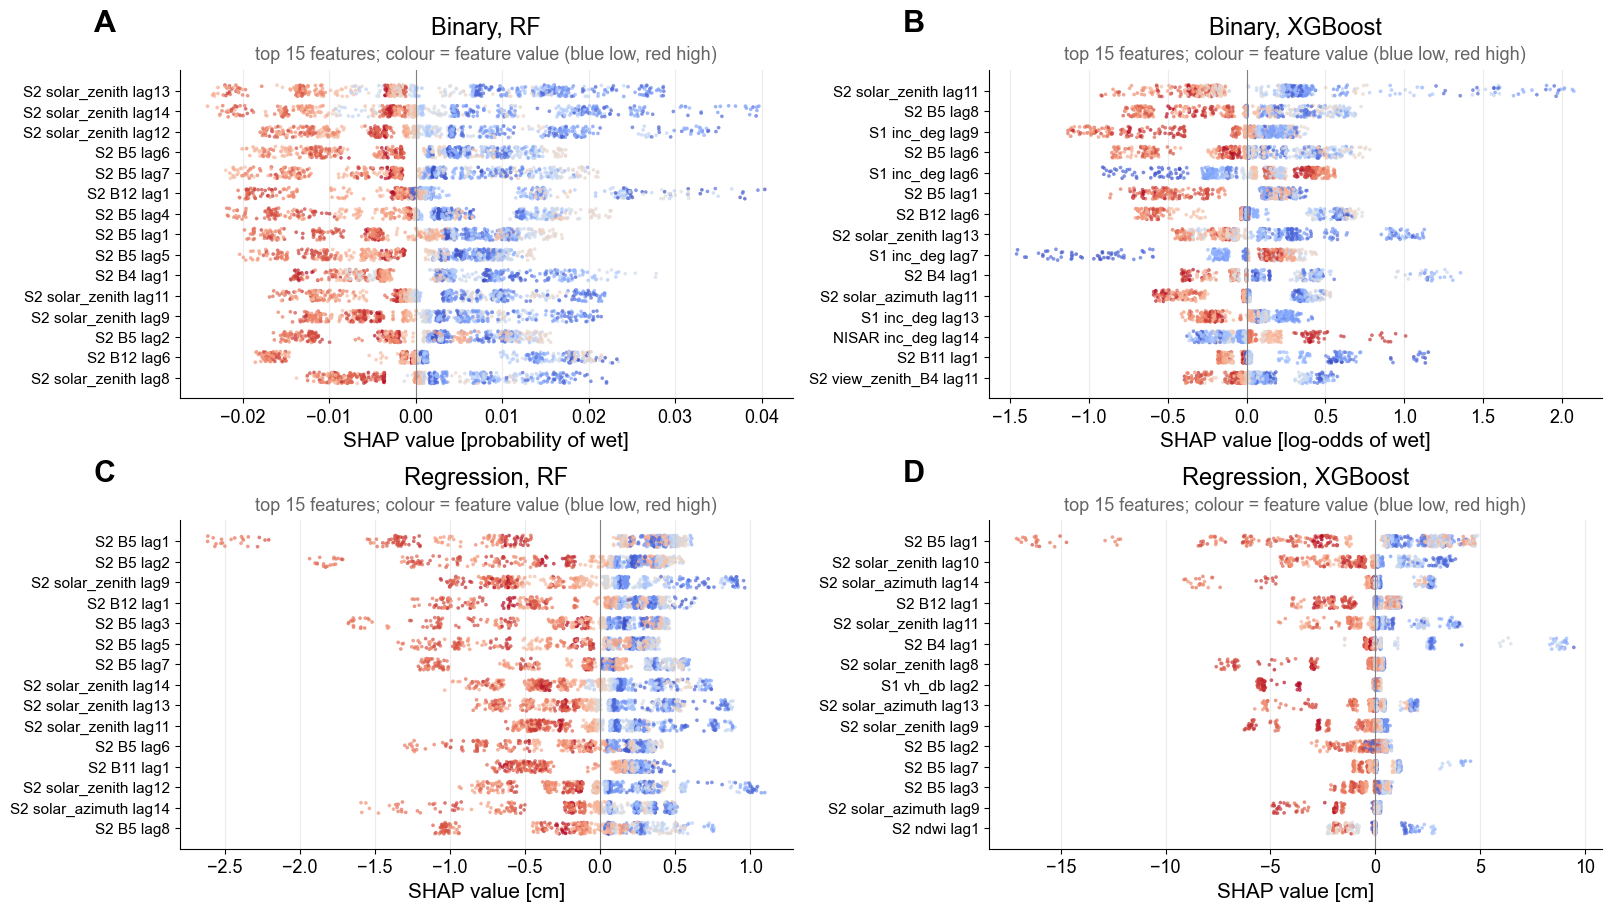

In [295]:
UNITS = {("binary", "RF"): "probability of wet", ("binary", "XGBoost"): "log-odds of wet",
         ("regression", "RF"): "cm", ("regression", "XGBoost"): "cm"}
TASK_TITLE = {"binary": "Binary", "3class": "3-class", "regression": "Regression"}

SHAP_VAR_TOP = 12          # variables shown per panel in the variable-importance figure

if RUN_SHAP:
    # ---- Figure 1: importance per variable (summed over lags), coloured by sensor ----
    for set_name in SHAP_SETS:
        fig, axes = plt.subplots(len(SHAP_TASKS), len(SHAP_MODELS),
                                 figsize=SLIDE_SIZE, layout="constrained", squeeze=False)
        for r, task in enumerate(SHAP_TASKS):
            for c, name in enumerate(SHAP_MODELS):
                ax = axes[r, c]
                v = shap_var[(shap_var.task == task) & (shap_var.set == set_name) & (shap_var.model == name)]
                n_all = len(v)
                v = v.sort_values("mean_abs_shap").tail(SHAP_VAR_TOP)       # top variables (all in the CSV)
                ax.barh([f"{s} {x}" for s, x in zip(v.sensor, v.variable)], v.mean_abs_shap,
                        color=[SENSOR_COLORS[s] for s in v.sensor])
                sh = shap_sensor[(shap_sensor.task == task) & (shap_sensor.set == set_name) & (shap_sensor.model == name)]
                share = ", ".join(f"{s} {p:.0%}" for s, p in zip(sh.sensor, sh.share))
                ax.set_title(f"{TASK_TITLE[task]}, {name}", pad=26)
                subtitle(ax, f"top {len(v)} of {n_all} variables; share of total: {share}")
                ax.set_xlabel(f"mean |SHAP|, summed over {WINDOW_DAYS} lags\n[{UNITS[(task, name)]}]")
                ax.tick_params(axis="y", labelsize=12)
                ax.grid(axis="x", alpha=0.25)
                panel_letter(ax, "ABCDEFGH"[r * len(SHAP_MODELS) + c])
        axes[-1, 0].legend(handles=[Patch(color=col, label=s) for s, col in SENSOR_COLORS.items()],
                           ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(1.1, -0.16))
        fig.savefig(OUT_DIR / f"shap_variables_{set_name}.png", dpi=SLIDE_DPI)
        plt.show()

    # ---- Figure 2: beeswarm of the top lag-features (one dot per field-day) ----
    for set_name in SHAP_SETS:
        fig, axes = plt.subplots(len(SHAP_TASKS), len(SHAP_MODELS),
                                 figsize=SLIDE_SIZE, layout="constrained",
                                 squeeze=False)
        rng = np.random.default_rng(SEED)
        for r, task in enumerate(SHAP_TASKS):
            for c, name in enumerate(SHAP_MODELS):
                ax = axes[r, c]
                S = shap_vals[(task, set_name, name)]
                S = S[[col for col in S.columns if not col.startswith("missingindicator_")]]
                top = S.abs().mean().sort_values(ascending=False).index[:SHAP_TOP][::-1]
                for i, col in enumerate(top):
                    vals = df[col]
                    colr = vals.rank(pct=True).fillna(0.5)                    # feature value as percentile
                    ax.scatter(S[col], i + rng.uniform(-0.28, 0.28, len(S)), c=colr, cmap="coolwarm",
                               s=7, alpha=0.7, linewidths=0, vmin=0, vmax=1)
                ax.set_yticks(range(len(top)))
                ax.set_yticklabels([f"{split_name(t)[0]} {split_name(t)[1]} lag{split_name(t)[2]}" for t in top],
                                   fontsize=11)
                ax.axvline(0, color="grey", lw=0.8)
                ax.set_xlabel(f"SHAP value [{UNITS[(task, name)]}]")
                ax.set_title(f"{TASK_TITLE[task]}, {name}", pad=26)
                subtitle(ax, f"top {SHAP_TOP} features; colour = feature value (blue low, red high)")
                ax.grid(axis="x", alpha=0.25)
                panel_letter(ax, "ABCDEFGH"[r * len(SHAP_MODELS) + c])
        fig.savefig(OUT_DIR / f"shap_beeswarm_{set_name}.png", dpi=SLIDE_DPI)
        plt.show()

    shap_imp.to_csv(OUT_DIR / "shap_feature_importance.csv", index=False)
    shap_var.to_csv(OUT_DIR / "shap_variable_importance.csv", index=False)
    shap_sensor.to_csv(OUT_DIR / "shap_sensor_share.csv", index=False)

### SHAP during the final drydown (end of season)

The same out-of-fold SHAP values, averaged over only the **final-drydown** days (after each field's last day with water ≥ 0 cm), next to the whole-season average. Only days with logger data are included, so this covers drainage up to the end of each logger record, not the period after it.

{'whole season': 602, 'final drydown': 58} field-days; final-drydown days per field: {'4 East': 7, 'S16': 12, 'South 0': 7, 'Way 3': 12, 'Way 4': 20}

Share of total mean |SHAP| by sensor, whole season vs final drydown
sensor                                NISAR     S1     S2
task       set model   period                            
binary     F5  RF      final drydown  0.038  0.118  0.844
                       whole season   0.040  0.092  0.868
               XGBoost final drydown  0.116  0.191  0.693
                       whole season   0.115  0.208  0.677
regression F5  RF      final drydown  0.057  0.117  0.826
                       whole season   0.060  0.082  0.858
               XGBoost final drydown  0.088  0.227  0.685
                       whole season   0.103  0.182  0.715


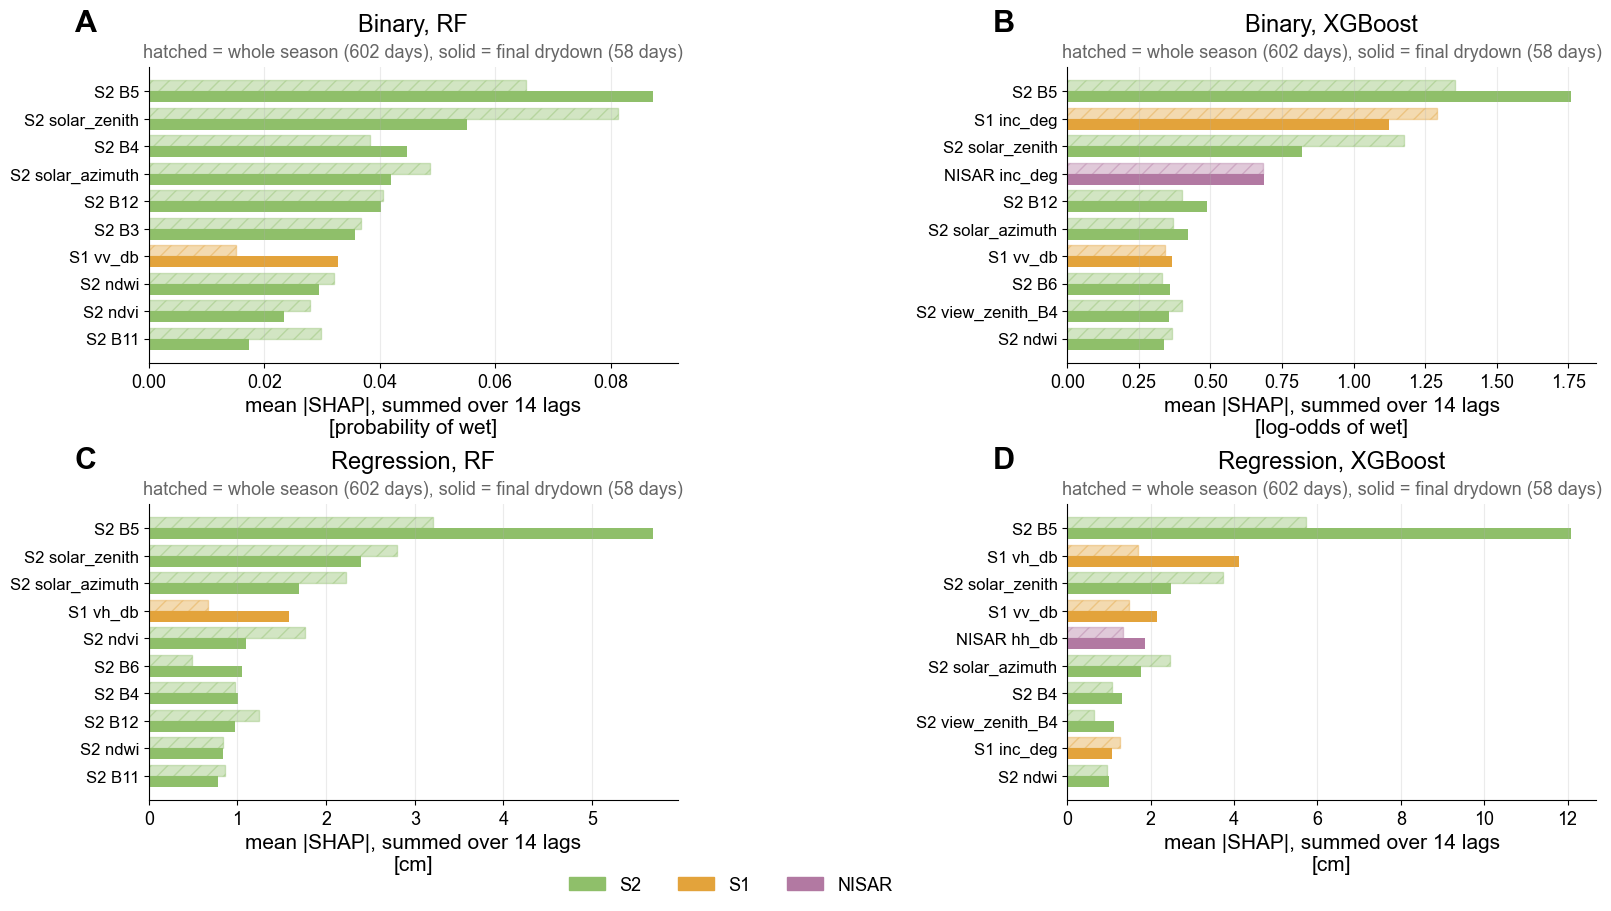

In [296]:
# SHAP importance averaged over a sub-period, next to the whole season.
# Final drydown = days after the LAST day with water >= DRY_2C in that field (end-of-season drainage before
# harvest), the same definition as the confusion-matrix section. The SHAP values are the out-of-fold
# values computed above, so nothing is refit here.
SHAP_TOP_VARS = 10          # variables shown per panel (ranked by the drydown period)

if RUN_SHAP:
    last_wet_day = df[df.water_cm >= DRY_2C].groupby("field").date.max()
    PERIODS = {"whole season": np.ones(len(df), bool),
               "final drydown": (df.date > df.field.map(last_wet_day)).values}
    print({p: int(m.sum()) for p, m in PERIODS.items()}, "field-days;",
          "final-drydown days per field:", df[PERIODS["final drydown"]].groupby("field").size().to_dict())

    rows = []
    for (task, set_name, name), S in shap_vals.items():
        for period, mask in PERIODS.items():
            per_col = S[mask].abs().mean()
            for col, v in per_col.items():
                sensor, var, lag = split_name(col)
                rows.append(dict(task=task, set=set_name, model=name, period=period, sensor=sensor,
                                 variable=var, mean_abs_shap=v))
    shap_period = (pd.DataFrame(rows).groupby(["task", "set", "model", "period", "sensor", "variable"])
                   .mean_abs_shap.sum().reset_index())
    sens = shap_period.groupby(["task", "set", "model", "period", "sensor"]).mean_abs_shap.sum()
    sens = (sens / sens.groupby(level=[0, 1, 2, 3]).transform("sum")).unstack("sensor")
    print("\nShare of total mean |SHAP| by sensor, whole season vs final drydown")
    print(sens.round(3).to_string())

    for set_name in SHAP_SETS:
        fig, axes = plt.subplots(len(SHAP_TASKS), len(SHAP_MODELS),
                                 figsize=SLIDE_SIZE, layout="constrained",
                                 squeeze=False)
        for r, task in enumerate(SHAP_TASKS):
            for c, name in enumerate(SHAP_MODELS):
                ax = axes[r, c]
                t = shap_period[(shap_period.task == task) & (shap_period.set == set_name) & (shap_period.model == name)]
                t = t.assign(label=t.sensor + " " + t.variable).pivot(index="label", columns="period", values="mean_abs_shap")
                t = t.sort_values("final drydown", ascending=False).head(SHAP_TOP_VARS)[::-1]
                y = np.arange(len(t)); h = 0.4
                colors = [SENSOR_COLORS[l.split(" ")[0]] for l in t.index]
                ax.barh(y + h / 2, t["whole season"], h, color=colors, alpha=0.4, hatch="//", edgecolor=colors,
                        label="whole season")
                ax.barh(y - h / 2, t["final drydown"], h, color=colors, label="final drydown")
                ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=12)
                ax.set_xlabel(f"mean |SHAP|, summed over {WINDOW_DAYS} lags\n[{UNITS[(task, name)]}]")
                n_dd = int(PERIODS["final drydown"].sum())
                ax.set_title(f"{TASK_TITLE[task]}, {name}", pad=26)
                subtitle(ax, f"hatched = whole season ({len(df)} days), solid = final drydown ({n_dd} days)")
                ax.grid(axis="x", alpha=0.25)
                panel_letter(ax, "ABCDEFGH"[r * len(SHAP_MODELS) + c])
        axes[-1, 0].legend(handles=[Patch(color=col, label=s) for s, col in SENSOR_COLORS.items()],
                           ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(1.1, -0.2))
        fig.savefig(OUT_DIR / f"shap_final_drydown_{set_name}.png", dpi=SLIDE_DPI)
        plt.show()
    shap_period.to_csv(OUT_DIR / "shap_variable_importance_by_period.csv", index=False)

## 5b. Random forest hyperparameter tuning (nested CV)

**Outer loop** = the same leave-one-field-group-out folds as above. **Inner loop** = a grid search on the training groups only (leave-one-group-out among them), scored with the task's primary metric. The best inner setting is refit on all training groups and scores the held-out group, so every held-out field is predicted with settings chosen without it.
With 3 training groups per outer fold, the inner search compares settings on 3 held-out groups; the chosen setting can differ between outer folds (table below).

In [297]:
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut

RUN_TUNING = False   # off for now
TUNE_SETS  = ["F3", "F5"]                 # feature sets to tune
TUNE_TREES = 300                          # trees during the search (final refit uses the same)
RF_GRID = {                               # random forest settings searched
    "max_depth":        [None, 3, 5, 10],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features":     ["sqrt", 0.3],
}
SCORER = {"binary": "balanced_accuracy", "3class": "f1_macro", "regression": "neg_root_mean_squared_error"}

tune_rows, choice_rows, grid_rows, tuned_oof = [], [], [], []
if RUN_TUNING:
    t0 = time.time()
    for task, target in TASKS.items():
        y = df[target].values.astype(float if task == "regression" else int)
        base = clone(make_models(task)["RF"][0]).set_params(**{f"{make_models(task)['RF'][0].steps[-1][0]}__n_estimators": TUNE_TREES})
        step = base.steps[-1][0]                          # e.g. "randomforestclassifier"
        grid = {f"{step}__{k}": v for k, v in RF_GRID.items()}
        for set_name in TUNE_SETS:
            X = df[feature_cols(set_name)]
            pred = np.full(len(y), np.nan); p1 = np.full(len(y), np.nan)
            for g in FOLDS:                               # outer folds
                te = groups == g; tr = ~te
                gs = GridSearchCV(base, grid, scoring=SCORER[task], cv=LeaveOneGroupOut(), n_jobs=1, refit=True)
                gs.fit(X[tr], y[tr], groups=groups[tr])
                pred[te] = gs.predict(X[te])
                if task == "binary":
                    pc = p_class1(gs.best_estimator_, X[te])
                    if pc is not None:
                        p1[te] = pc
                best = {k.split("__", 1)[1]: v for k, v in gs.best_params_.items()}
                inner = -gs.best_score_ if task == "regression" else gs.best_score_
                choice_rows.append(dict(task=task, set=set_name, outer_fold=g, inner_best_score=inner, **best,
                                        **{f"test_{PRIMARY_METRIC[task]}": metrics(task, y[te], pred[te],
                                           p1[te] if task == "binary" else None)[PRIMARY_METRIC[task]]}))
                cvr = pd.DataFrame(gs.cv_results_)
                for _, r in cvr.iterrows():
                    grid_rows.append(dict(task=task, set=set_name, outer_fold=g,
                                          **{k.split("__", 1)[1]: r[f"param_{k}"] for k in grid},
                                          mean_inner_score=(-r.mean_test_score if task == "regression" else r.mean_test_score),
                                          std_inner_score=r.std_test_score))
            pp = p1 if task == "binary" else None
            m = metrics(task, y, pred, pp)[PRIMARY_METRIC[task]]
            fold_m = [metrics(task, y[groups == g], pred[groups == g], None if pp is None else pp[groups == g])[PRIMARY_METRIC[task]]
                      for g in FOLDS]
            untuned = pooled[(pooled.task == task) & (pooled.set == set_name) & (pooled.model == "RF")][PRIMARY_METRIC[task]].iloc[0]
            untuned_f = by_fold[(by_fold.task == task) & (by_fold.set == set_name) & (by_fold.model == "RF")][PRIMARY_METRIC[task]]
            tune_rows.append(dict(task=task, set=set_name, metric=PRIMARY_METRIC[task],
                                  untuned_pooled=untuned, tuned_pooled=m,
                                  untuned_fold_mean=untuned_f.mean(), untuned_fold_sd=untuned_f.std(),
                                  tuned_fold_mean=np.mean(fold_m), tuned_fold_sd=np.std(fold_m, ddof=1)))
            tuned_oof.append(pd.DataFrame(dict(task=task, set=set_name, row=np.arange(len(y)), y=y, pred=pred,
                                               proba1=p1 if task == "binary" else np.nan)))
            print(f"{task} {set_name}: done ({time.time() - t0:.0f} s)")

    tuning = pd.DataFrame(tune_rows); rf_choices = pd.DataFrame(choice_rows); rf_grid = pd.DataFrame(grid_rows)
    print("\nPrimary metric, untuned RF (config RF_PARAMS) vs tuned RF (nested CV)")
    print(tuning.round(3).to_string(index=False))
    print("\nSettings chosen in each outer fold (inner-CV best), and that fold's test score")
    print(rf_choices.round(3).to_string(index=False))
    tuning.to_csv(OUT_DIR / "rf_tuning_summary.csv", index=False)
    rf_choices.to_csv(OUT_DIR / "rf_tuning_choices.csv", index=False)
    rf_grid.to_csv(OUT_DIR / "rf_tuning_grid.csv", index=False)
    pd.concat(tuned_oof, ignore_index=True).to_csv(OUT_DIR / "rf_tuned_oof_predictions.csv", index=False)

### Figure: untuned vs tuned random forest (fold mean ± SD)

In [298]:
if RUN_TUNING:
    fig, axes = plt.subplots(1, len(TASKS), figsize=SLIDE_SIZE, layout="constrained")
    for k, (ax, task) in enumerate(zip(np.atleast_1d(axes), TASKS)):
        t = tuning[tuning.task == task].set_index("set").loc[TUNE_SETS]
        x = np.arange(len(TUNE_SETS)); w = 0.38
        for j, (kind, hatch, alpha) in enumerate((("untuned", "//", 0.45), ("tuned", None, 1.0))):
            ax.bar(x + (j - 0.5) * w, t[f"{kind}_fold_mean"], w, yerr=t[f"{kind}_fold_sd"], capsize=3,
                   color=[set_colors[s] for s in TUNE_SETS], alpha=alpha, hatch=hatch,
                   edgecolor=[set_colors[s] for s in TUNE_SETS], error_kw=dict(lw=0.9, ecolor="#444444"),
                   label=kind)
            ax.plot(x + (j - 0.5) * w, t[f"{kind}_pooled"], "k_", ms=18, mew=2,
                    label="pooled" if j == 1 else None)
        metric = PRIMARY_METRIC[task]
        ax.set_xticks(x); ax.set_xticklabels(TUNE_SETS); ax.set_ylabel(metric.replace("_", " "))
        ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
        subtitle(ax, "hatched = untuned, solid = tuned; bars = fold mean ± SD, — = pooled")
        ax.grid(axis="y", alpha=0.25)
        panel_letter(ax, "ABC"[k])
    fig.savefig(OUT_DIR / "rf_tuning.png", dpi=SLIDE_DPI)
    plt.show()

## 6. Hold-out test (only if `HOLDOUT_FIELDS` is set)

Each model is refit once on **all** development rows and scored once on the locked hold-out field. No choices are made from these numbers.
Note: with few days of a class in the hold-out field, its macro-F1 is dominated by those days (e.g. 4 East has 1 middle-class day).

In [299]:
ho_rows, ho_pred_rows = [], []
if RUN_HOLDOUT:
    for task, target in TASKS.items():
        cast = float if task == "regression" else int
        y_dev, y_te = df[target].values.astype(cast), df_test[target].values.astype(cast)
        for set_name in FEATURE_SETS:
            cols = feature_cols(set_name)
            for name, (est, how) in make_models(task).items():
                m = clone(est).fit(model_input(df[cols], how), y_dev)
                X_te = model_input(df_test[cols], how, frame=df_test)
                pred = m.predict(X_te)
                p1 = None
                if task == "binary" and hasattr(m, "predict_proba"):
                    cls = list(m.classes_)
                    p1 = m.predict_proba(X_te)[:, cls.index(1)] if 1 in cls else np.zeros(len(y_te))
                ho_rows.append(dict(task=task, set=set_name, model=name, n=len(y_te), **metrics(task, y_te, pred, p1)))
                ho_pred_rows.append(pd.DataFrame(dict(task=task, set=set_name, model=name, unit=df_test.unit,
                                                      date=df_test.date, y=y_te, pred=pred,
                                                      proba1=p1 if p1 is not None else np.nan)))
    holdout = pd.DataFrame(ho_rows); holdout_pred = pd.concat(ho_pred_rows, ignore_index=True)
    print(f"hold-out field(s): {HOLDOUT_FIELDS}, n = {len(df_test)} days")
    for task, metric in PRIMARY_METRIC.items():
        t = holdout[holdout.task == task].pivot(index="model", columns="set", values=metric).loc[list(make_models(task))]
        print(f"\n{task} — {metric} (hold-out)")
        print(t.round(3).to_string())

### Figure: hold-out water level, observed vs predicted (primary model, F4 vs F5)

In [300]:
if RUN_HOLDOUT:
    fig, ax = plt.subplots(figsize=SLIDE_SIZE, layout="constrained")
    ax.plot(df_test.date, df_test.water_cm, color="k", lw=2, label="observed")
    r = holdout_pred[(holdout_pred.task == "regression") & (holdout_pred.model == PRIMARY_MODEL)]
    for s, c in zip(TEST_SETS, ["#d62728", "#4c78a8"]):
        rr = r[r.set == s]
        rmse = holdout[(holdout.task == "regression") & (holdout.model == PRIMARY_MODEL) & (holdout.set == s)].rmse.iloc[0]
        ax.plot(rr.date, rr.pred, color=c, lw=1.5, label=f"{s} prediction (RMSE {rmse:.1f} cm)")
    ax.axhline(0, color="grey", lw=0.8, ls="--"); ax.set_ylabel("water level (cm)")
    ax.set_title(f"Hold-out: {', '.join(HOLDOUT_FIELDS)} — {PRIMARY_MODEL} regression")
    ax.legend(loc="lower left", frameon=False)
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.savefig(OUT_DIR / "holdout_water_level_primary.png", dpi=SLIDE_DPI)
    plt.show()

## 7. Hypothesis test: F5 vs F3 (primary model)

Δ = metric(F5) − metric(F3), signed so that **Δ > 0 means F5 is better** (for RMSE: Δ = RMSE(F3) − RMSE(F5)).

* **Permutation test.** Each field's NISAR feature series is replaced by another field's series on the same dates (all n! permutations of the n development fields, identity included; 4 fields → 24), and the full F5 cross-validation is refit. p = share of permutations with Δ ≥ observed Δ. Smallest possible p = 1/n!. Way 3 and Way 4 are adjacent, so swaps between them change the NISAR series less than other swaps.
* **Bootstrap CI.** On the fixed out-of-fold predictions: resample the development fields with replacement, then within each sampled field resample its `BLOCK_DAYS`-day blocks (per unit) with replacement. 95 % percentile CI of Δ.

In [301]:
def delta(task, y, pred_with, pred_without, p_with=None, p_without=None):
    metric = PRIMARY_METRIC[task]
    a = metrics(task, y, pred_with, p_with)[metric]; b = metrics(task, y, pred_without, p_without)[metric]
    return (b - a) if metric in LOWER_IS_BETTER else (a - b)

nisar_cols = [c for c in feature_cols(TEST_SETS[0]) if c.startswith(SENSORS["NISAR"])]
fields = sorted(df.field.unique())

def permuted_X(perm):
    # F5 features with each field's NISAR columns taken from field perm[field] on the same date.
    X = df[feature_cols(TEST_SETS[0])].copy()
    donor = df.field.map(perm)
    X[nisar_cols] = fields_tbl.reindex(pd.MultiIndex.from_arrays([donor, df.date]))[nisar_cols].values
    return X

def all_perms():
    perms = [dict(zip(fields, p)) for p in itertools.permutations(fields)]
    if N_PERM == "all":
        return perms
    rng = np.random.default_rng(SEED)
    ident = dict(zip(fields, fields))
    return [ident] + [perms[i] for i in rng.choice(len(perms), size=int(N_PERM), replace=False)]

# Bootstrap units: field -> list of row-index arrays (unit x block)
df["_block"] = df.groupby("unit").date.transform(lambda d: ((d - d.min()).dt.days // BLOCK_DAYS))
units = {f: [g.index.values for _, g in df[df.field == f].groupby(["unit", "_block"])] for f in fields}

def boot_ci(task, y, pw, pwo, p1w, p1wo):
    rng = np.random.default_rng(SEED); out = []
    for _ in range(N_BOOT):
        idx = np.concatenate([u for f in rng.choice(fields, len(fields), replace=True)
                              for u in (lambda us: [us[i] for i in rng.integers(0, len(us), len(us))])(units[f])])
        yy = y[idx]
        if task != "regression" and len(np.unique(yy)) < 2:
            continue
        out.append(delta(task, yy, pw[idx], pwo[idx],
                         None if p1w is None else p1w[idx], None if p1wo is None else p1wo[idx]))
    return np.percentile(out, [2.5, 97.5]), len(out)

In [302]:
sig_rows, null_rows = [], []
if RUN_SIGNIFICANCE:
    perms = all_perms()
    est_by_task = {t: make_models(t)[PRIMARY_MODEL][0] for t in TASKS}
    for task, target in TASKS.items():
        y = df[target].values.astype(float if task == "regression" else int)
        o = oof[(oof.task == task) & (oof.model == PRIMARY_MODEL)]
        w, wo = (o[o.set == s].sort_values("row") for s in TEST_SETS)
        p1w = w.proba1.values if task == "binary" else None
        p1wo = wo.proba1.values if task == "binary" else None
        d_obs = delta(task, y, w.pred.values, wo.pred.values, p1w, p1wo)

        t0 = time.time(); d_null = []
        for i, perm in enumerate(perms):
            pred, p1 = run_cv(est_by_task[task], permuted_X(perm), y, task)
            d = delta(task, y, pred, wo.pred.values, p1, p1wo)
            d_null.append(d)
            null_rows.append(dict(task=task, perm=i, identity=all(k == v for k, v in perm.items()),
                                  mapping=str(perm), delta=d))
            if (i + 1) % 20 == 0:
                print(f"  {task}: {i + 1}/{len(perms)} permutations ({time.time() - t0:.0f} s)")
        d_null = np.array(d_null)
        ci, n_ok = boot_ci(task, y, w.pred.values, wo.pred.values, p1w, p1wo)
        sig_rows.append(dict(task=task, metric=PRIMARY_METRIC[task], model=PRIMARY_MODEL,
                             F5=metrics(task, y, w.pred.values, p1w)[PRIMARY_METRIC[task]],
                             F3=metrics(task, y, wo.pred.values, p1wo)[PRIMARY_METRIC[task]],
                             delta=d_obs, perm_p=np.mean(d_null >= d_obs - 1e-12), n_perm=len(d_null),
                             boot_ci_low=ci[0], boot_ci_high=ci[1], n_boot=n_ok))
    sig = pd.DataFrame(sig_rows); perm_null = pd.DataFrame(null_rows)
    print(); print(sig.round(4).to_string(index=False))

### Figure: permutation null distributions

In [303]:
if RUN_SIGNIFICANCE:
    fig, axes = plt.subplots(1, len(TASKS), figsize=SLIDE_SIZE, layout="constrained")
    for ax, task in zip(np.atleast_1d(axes), TASKS):
        d = perm_null[perm_null.task == task]; s = sig[sig.task == task].iloc[0]
        ax.hist(d.delta, bins=25, color="#bbbbbb", edgecolor="white")
        ax.axvline(s.delta, color="#d62728", lw=2.5, label=f"observed Δ = {s.delta:.3f}")
        ax.set_title(f"{task}\npermutation p = {s.perm_p:.3f} (n = {int(s.n_perm)})")
        ax.set_xlabel(f"Δ {PRIMARY_METRIC[task]} (F5 better →)"); ax.set_ylabel("permutations")
        ax.legend(loc="upper left", fontsize=12, frameon=False)
        panel_letter(ax, "ABC"[list(TASKS).index(task)])
    fig.savefig(OUT_DIR / "permutation_null.png", dpi=SLIDE_DPI)
    plt.show()

## 8. Save

In [304]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
pooled.to_csv(OUT_DIR / "results_pooled.csv", index=False)
by_fold.to_csv(OUT_DIR / "results_by_fold.csv", index=False)
fold_stats.to_csv(OUT_DIR / "results_fold_mean_sd.csv", index=False)
by_fold_train.to_csv(OUT_DIR / "results_train_by_fold.csv", index=False)
train_test.to_csv(OUT_DIR / "results_train_vs_test.csv", index=False)
oof.merge(df[["unit", "field", "group", "date"]], left_on="row", right_index=True) \
   .to_csv(OUT_DIR / "oof_predictions.csv", index=False)
if RUN_HOLDOUT:
    holdout.to_csv(OUT_DIR / "results_holdout.csv", index=False)
    holdout_pred.to_csv(OUT_DIR / "holdout_predictions.csv", index=False)
if RUN_SIGNIFICANCE:
    sig.to_csv(OUT_DIR / "significance_F5_vs_F3.csv", index=False)
    perm_null.to_csv(OUT_DIR / "permutation_null.csv", index=False)
print("saved to", OUT_DIR.relative_to(ROOT), ":", sorted(p.name for p in OUT_DIR.iterdir()))

saved to outputs/model : ['binary_cm_4_East.png', 'binary_cm_S16.png', 'binary_cm_South_0.png', 'binary_cm_Way_3.png', 'binary_cm_Way_4.png', 'binary_final_drydown_summary.csv', 'fold_mean_sd_by_model.png', 'oof_predictions.csv', 'oof_water_level_primary.png', 'primary_metric_by_model.png', 'results_by_fold.csv', 'results_fold_mean_sd.csv', 'results_pooled.csv', 'results_train_by_fold.csv', 'results_train_vs_test.csv', 'rf_tuned_oof_predictions.csv', 'rf_tuning.png', 'rf_tuning_choices.csv', 'rf_tuning_grid.csv', 'rf_tuning_summary.csv', 'shap_beeswarm_F5.png', 'shap_feature_importance.csv', 'shap_final_drydown_F5.png', 'shap_sensor_share.csv', 'shap_variable_importance.csv', 'shap_variable_importance_by_period.csv', 'shap_variables_F5.png', 'train_vs_test_by_model.png']
